# Tugas Kelompok 2: *Data Collection Pipeline* YouTube — Program Makan Bergizi Gratis (MBG)

## Anggota Kelompok

1. Erland Hafizh Aristovi (2306165686)
2. Jasmine Rakhaila (2306165774)
3. Leonita Cecilia (2306165710)
4. Yeshua Marco Gracia Manurung (2306210286)

**Judul penelitian:** Analisis Kekhawatiran Publik terhadap Kebersihan dan Keamanan Pangan Program Makan Bergizi Gratis (MBG) pada Media Sosial YouTube dan X.

Notebook ini adalah bagian **YouTube** dari *pipeline* pengumpulan data. Data X dikumpulkan secara terpisah melalui *web scraping*, lalu kedua sumber digabung memakai skema yang sama (bagian 2.6.2).

## Ringkasan Pipeline

| Pertanyaan penelitian | Data YouTube yang dibutuhkan |
|---|---|
| RQ1: jenis masalah keamanan & kebersihan makanan MBG | Judul, deskripsi video, dan teks komentar |
| RQ2: variasi masalah antarwilayah | Judul & deskripsi video (penyebutan lokasi insiden), comment, waktu terbit → kolom lokasi (bagian 2.4) |
| RQ3: kekhawatiran/keluhan publik | Teks komentar & balasan, waktu, jumlah *like* |

```
 Daftar 28 channel (27 media nasional + BGN)
            │
            ▼
 [1.7] channels.list ──► info channel, uploads playlist, jumlah video
            │
            ├── channel ≤ 20.000 video ──► [1.8] playlistItems.list (uploads playlist)
            └── channel > 20.000 video ──► [1.9] search.list (keyword MBG per kuartal)
            │
            ▼
 [1.11] Gabung kandidat + hapus duplikat video_id
            │
            ▼
 [1.12] videos.list (batch 50) ──► [1.13] validasi channel, periode, keyword MBG
            │
            ▼
 [1.14] commentThreads.list + comments.list ──► semua comment + reply
            │
            ▼
 [2] Preprocessing + [2.4] ekstraksi lokasi (kamus wilayah)
            │
            ▼
 videos_clean, comments_clean, youtube_unified (siap digabung dengan X)
            │
            ▼
 [3] Exploratory Data Analysis
```

Semua langkah memakai **YouTube Data API v3** melalui library `requests`. Kuota harian API terbatas (10.000 unit untuk endpoint umum dan 100 panggilan `search.list`), sehingga pengumpulan dapat memerlukan beberapa hari. Setiap progres disimpan di folder `data/raw/youtube/state/`. Jika kuota habis, jalankan ulang notebook keesokan harinya, maka proses melanjutkan dari titik terakhir.

# 1. Pengumpulan Data

## 1.1. Import Library

Mengimpor library yang dibutuhkan untuk keseluruhan proses pengambilan dan pengolahan data, yaitu:

* `requests` untuk melakukan HTTP request ke YouTube Data API.
* `pandas` dan `numpy` untuk mengolah dan menyimpan data dalam bentuk tabel (DataFrame/CSV).
* `matplotlib` dan `wordcloud` untuk visualisasi pada bagian EDA.
* `json` untuk menyimpan data mentah dan progres pengumpulan.
* `time` untuk memberi jeda sebelum mencoba ulang request yang gagal.
* `hashlib` dan `secrets` untuk membuat pseudonim penulis comment.
* `html`, `unicodedata`, dan `re` untuk membersihkan teks.
* `python-dotenv` (diimpor saat membaca API key) untuk membaca API key dari file `.env`.

In [1]:
import os
import re
import json
import time
import html
import hashlib
import secrets
import unicodedata
from collections import Counter
from pathlib import Path
from datetime import datetime, timezone
from getpass import getpass

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_colwidth", 80)

## 1.2. Konfigurasi Penelitian

Mendefinisikan seluruh parameter penelitian dalam satu sel agar mudah diperiksa dan dilaporkan:

* `PERIOD_START` dan `PERIOD_END`: periode **tanggal terbit video** dalam WIB, mulai 6 Januari 2025 (awal pelaksanaan MBG) sampai 30 September 2026. Comment tidak dibatasi tanggalnya; semua comment pada video terpilih diambil sampai waktu pengambilan.
* `MBG_PATTERN`: regex untuk memvalidasi judul/deskripsi video. Video dianggap relevan jika memuat kata `MBG` atau frasa `makan bergizi gratis` / `makanan bergizi gratis`. Pola dibuat luas agar dataset induk mencakup seluruh pembahasan MBG; pemilahan topik keamanan pangan dilakukan pada tahap analisis.
* `SEARCH_QUERY`: query untuk `search.list`. Operator `|` berarti ATAU.
* `MAX_UNITS_PER_SESSION` dan `MAX_SEARCH_CALLS_PER_SESSION`: pengaman agar satu sesi tidak menghabiskan seluruh kuota harian.
* `COLLECT_DATA`: `True` untuk mengambil/melanjutkan data dari API; `False` untuk hanya menjalankan preprocessing dan EDA pada data yang sudah tersimpan (tidak memerlukan API key).

In [2]:
PERIOD_START = "2025-01-06"
PERIOD_END = "2026-09-30"  # inklusif

MBG_PATTERN = r"\bmbg\b|\bmakan(an)?\s+bergizi\s+gratis\b"
SEARCH_QUERY = 'MBG|"makan bergizi gratis"'

MAX_UNITS_PER_SESSION = 9000        # kuota default harian: 10.000 unit
MAX_SEARCH_CALLS_PER_SESSION = 100  # kuota default harian: 100 panggilan search.list

COLLECT_DATA = True

In [3]:
# API YouTube memakai waktu UTC, jadi batas periode WIB (UTC+7) dikonversi ke UTC.
START_UTC = pd.Timestamp(f"{PERIOD_START}T00:00:00+07:00").tz_convert("UTC")
END_UTC = pd.Timestamp(f"{PERIOD_END}T00:00:00+07:00").tz_convert("UTC") + pd.Timedelta(days=1)
MBG_REGEX = re.compile(MBG_PATTERN, re.IGNORECASE)

print("Periode video (UTC):", START_UTC, "sampai sebelum", END_UTC)

Periode video (UTC): 2025-01-05 17:00:00+00:00 sampai sebelum 2026-09-30 17:00:00+00:00


## 1.3. Daftar Channel Sumber

Mendefinisikan daftar channel YouTube yang menjadi sumber data, yaitu **27 channel media nasional** dan **1 channel resmi Badan Gizi Nasional (BGN)**. Alasan pemilihan:

* Media nasional memberitakan insiden MBG dari berbagai daerah, sehingga mendukung RQ2 tanpa perlu mengumpulkan puluhan channel daerah.
* Channel BGN mewakili komunikasi resmi pemerintah dan **dibedakan** dari media melalui kolom `category`.
* Setiap `channel_id` sudah diverifikasi dari situs resmi penerbit atau dikonfirmasi peneliti (bukti tersimpan di `youtube_channel_registry.json`), sehingga channel tiruan atau *fan page* tidak ikut terambil.

In [4]:
CHANNELS = [
    # (record_id, channel_name, channel_id, category)
    ("N001", "KOMPASTV", "UC5BMIWZe9isJXLZZWPWvBlg", "national_media"),
    ("N002", "CNN Indonesia", "UCKII0Ml9S5wneKbHswmUrIQ", "national_media"),
    ("N003", "METRO TV", "UCzl0OrB3-ehunyotIQvK77A", "national_media"),
    ("N004", "tvOneNews", "UCER4rvDnRBPr_ncYW4UCZjg", "national_media"),
    ("N005", "Official iNews", "UCoSkllfpgmFHtbVK835QaQg", "national_media"),
    ("N006", "BeritaSatu", "UCqLsfkQSM0yfyGvONAGWd3Q", "national_media"),
    ("N007", "TVRI Nasional", "UCyIMsCzDRm8_y_6wM26_PWQ", "national_media"),
    ("N008", "RRI NET OFFICIAL", "UCyUr8PM0PFwYQAy5yUPH36Q", "national_media"),
    ("N009", "GARUDA TV", "UCmXp0n4Oq8DGzjRZj3EvG4Q", "national_media"),
    ("N010", "CNBC Indonesia", "UCGN9JsnkvK05v2lnTI_-uGA", "national_media"),
    ("N011", "Kompas.com", "UCPAxpUn1mrn14xU0JpsLhDg", "national_media"),
    ("N012", "detikcom", "UCuMAjEaSMj7q7YLf0xW1MjQ", "national_media"),
    ("N013", "Tribunnews", "UCmxAIW7RDDC88EPk4ry16Kg", "national_media"),
    ("N014", "Liputan6", "UC1QpnGo11epfexw1bIiTHTg", "national_media"),
    ("N015", "kumparan", "UCm2Fz7aL464TC_0uG_yagng", "national_media"),
    ("N016", "Antara TV Indonesia", "UCAXcJqVpDHSfr_MdEuclSCg", "national_media"),
    ("N017", "Tempodotco", "UC3QRoNY-nYDTNSv-1dR0P-g", "national_media"),
    ("N018", "Narasi Newsroom", "UCnOf30K0d0e8M7mc4FUzR0A", "national_media"),
    ("N019", "IDN TIMES", "UCMcqmnF-uCBFzQ3NvmaELCg", "national_media"),
    ("N020", "Suaradotcom", "UCeq1WeHIbMyeKp_sUNolgzA", "national_media"),
    ("N021", "medcom id", "UCjEz1Z4kKpb5T6HzFw_qlzA", "national_media"),
    ("N022", "JPNN.COM", "UCHYuEi41c1RcoTf8NgJLdkg", "national_media"),
    ("N023", "MerdekaDotCom", "UCdOovgmIPfj9a-o3VP5i2_g", "national_media"),
    ("N024", "SINDOnews", "UCGfXjFgIUUTUUlzdG6BenXA", "national_media"),
    ("N025", "REPUBLIKA Official", "UCWBqcKLh_Ta6ua00OX57ejA", "national_media"),
    ("N029", "VIVA.CO.ID", "UCB1fvlA5xmLJ0tZblpoTuaQ", "national_media"),
    ("N030", "Okezone", "UCHc8PjWfjZUFVmPQeLcFT2g", "national_media"),
    ("G001", "Badan Gizi Nasional Republik Indonesia", "UC3USej-LVYCple4BOOLGYTg", "government"),
]
df_channels = pd.DataFrame(CHANNELS, columns=["record_id", "channel_name", "channel_id", "category"])

# Pastikan tidak ada channel_id ganda.
assert df_channels["channel_id"].is_unique, "Ada channel_id ganda pada daftar channel."
print(f"{len(df_channels)} channel:", df_channels["category"].value_counts().to_dict())

28 channel: {'national_media': 27, 'government': 1}


## 1.4. Folder Penyimpanan dan Fungsi Helper File

Menyiapkan folder penyimpanan. Notebook dijalankan dari folder `youtube/` atau dari folder proyek (di Colab: `%cd` ke folder proyek terlebih dahulu). Semua data disimpan di folder `data/` pada folder proyek, mengikuti struktur repositori kelompok:

| Folder | Isi |
|---|---|
| `data/raw/youtube/api/` | Respons asli API dalam format JSON Lines (satu baris per request), tidak pernah diubah |
| `data/raw/youtube/state/` | Progres pencarian per channel dan status comment per video, dipakai untuk melanjutkan (*resume*) |
| `data/raw/youtube/comments/` | Comment per video (CSV), ditulis setelah satu video selesai |
| `data/raw/youtube/logs/` | Log setiap request API (waktu, endpoint, status) untuk menghitung pemakaian kuota |
| `data/interim/youtube/` | Dataset bersih dan tabel ringkasan, siap digabung dengan data X |
| `youtube/figures/` | Grafik EDA untuk laporan |

Fungsi helper `save_json()` dan `save_csv()` menulis ke file sementara terlebih dahulu lalu menggantinya (`replace`), sehingga file tidak rusak setengah jadi jika notebook terhenti di tengah penulisan.

In [5]:
# Folder proyek = induk dari folder youtube/ (di Colab: %cd ke folder proyek terlebih dahulu).
BASE_DIR = Path.cwd().parent if Path.cwd().name == "youtube" else Path.cwd()
YOUTUBE_RAW_DIR = BASE_DIR / "data" / "raw" / "youtube"
RAW_DIR = YOUTUBE_RAW_DIR / "api"
STATE_DIR = YOUTUBE_RAW_DIR / "state"
COMMENT_DIR = YOUTUBE_RAW_DIR / "comments"
LOG_DIR = YOUTUBE_RAW_DIR / "logs"
OUTPUT_DIR = BASE_DIR / "data" / "interim" / "youtube"
FIGURE_DIR = BASE_DIR / "youtube" / "figures"

for folder in [RAW_DIR, STATE_DIR, COMMENT_DIR, LOG_DIR, OUTPUT_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Folder proyek:", BASE_DIR)

Folder run: z:\Universitas Indonesia\Semester 7\Anmedsos\Tugas\TK2\Youtube\FINAL\data\v2\mbg_youtube_v2


In [6]:
def now_utc():
    # Waktu UTC format ISO, untuk mencatat kapan data diambil.
    return datetime.now(timezone.utc).isoformat()


def save_json(path, data):
    tmp_path = Path(str(path) + ".tmp")
    tmp_path.write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding="utf-8")
    tmp_path.replace(path)


def load_json(path, default):
    return json.loads(Path(path).read_text(encoding="utf-8")) if Path(path).exists() else default


def save_csv(df, path):
    tmp_path = Path(str(path) + ".tmp")
    df.to_csv(tmp_path, index=False, encoding="utf-8")
    tmp_path.replace(path)


def load_csv(path):
    # Semua kolom dibaca sebagai teks; konversi tipe data dilakukan pada tahap preprocessing.
    if not Path(path).exists():
        return pd.DataFrame()
    return pd.read_csv(path, dtype=str, keep_default_na=False)


def append_jsonl(path, data):
    with open(path, "a", encoding="utf-8") as f:
        f.write(json.dumps(data, ensure_ascii=False) + "\n")

## 1.5. API Key YouTube

Mengambil API key YouTube **tanpa menuliskannya di dalam kode**. Fungsi `get_api_key()` mencari key secara berurutan dari:

1. *environment variable* `YT_API_KEY` atau `YOUTUBE_API_KEY`;
2. file `.env` di folder proyek (isi: `YT_API_KEY=...`; file ini tidak ikut diunggah ke GitHub);
3. Colab Secret bernama `YT_API_KEY`;
4. input tersembunyi (`getpass`).

Untuk memastikan key terdeteksi, yang dicetak hanya panjang key, bukan isinya. Jika `COLLECT_DATA = False`, API key tidak diminta.

In [7]:
def get_api_key():
    key_names = ["YT_API_KEY", "YOUTUBE_API_KEY"]
    for name in key_names:
        value = os.environ.get(name)
        if value:
            return value.strip()

    env_file = BASE_DIR / ".env"
    if env_file.exists():
        from dotenv import dotenv_values
        env_values = dotenv_values(env_file)
        for name in key_names:
            value = env_values.get(name)
            if value:
                return value.strip()

    try:
        from google.colab import userdata  # Google Colab.
        value = userdata.get("YT_API_KEY")
        if value:
            return value.strip()
    except Exception:
        pass

    return getpass("Masukkan YouTube API key (tidak disimpan): ").strip()


API_KEY = get_api_key() if COLLECT_DATA else None
if COLLECT_DATA:
    print("API key terdeteksi (disembunyikan). Panjang:", len(API_KEY))
else:
    print("COLLECT_DATA = False: pengambilan data dilewati, langsung memakai data tersimpan.")

API key terdeteksi (disembunyikan). Panjang: 39


## 1.6. Fungsi Helper untuk Memanggil YouTube Data API

Mendefinisikan fungsi `youtube_get()` sebagai *wrapper* untuk semua pemanggilan YouTube Data API v3, sehingga perilaku setiap request seragam. Fungsi ini:

* **Menghitung pemakaian kuota.** Setiap request (termasuk percobaan ulang) dihitung. Endpoint umum memakai 1 unit per request, sedangkan `search.list` dihitung terpisah karena memiliki kuota sendiri. Jika batas sesi tercapai, fungsi melempar `QuotaExceeded`, dan progres yang sudah tersimpan tetap aman.
* **Menangani error.** Error jaringan, HTTP `429`, dan `5xx` dicoba ulang hingga 3 kali dengan jeda bertambah (2 lalu 4 detik). Error `quotaExceeded` dari API menghentikan sesi. Error lain (misalnya `commentsDisabled`) diteruskan sebagai `ApiError` untuk ditangani oleh fungsi pemanggil.
* **Menyimpan data mentah.** Setiap respons sukses disimpan apa adanya ke `raw/<endpoint>.jsonl` beserta parameter dan waktu pengambilan. API key tidak ikut disimpan.
* **Mencatat log** setiap request ke `logs/api_calls.csv`.

In [8]:
class QuotaExceeded(Exception):
    # Dilempar ketika kuota harian API atau batas sesi sudah habis.
    def __init__(self, quota_type):
        self.quota_type = quota_type  # "unit" (endpoint umum) atau "search"
        super().__init__(f"Kuota {quota_type} habis")


class ApiError(Exception):
    # Error dari API yang bukan masalah kuota, misalnya comment dinonaktifkan.
    def __init__(self, reason, status):
        self.reason = reason
        self.status = status
        super().__init__(f"{reason} (HTTP {status})")


usage = {"unit": 0, "search": 0}  # Penghitung request pada sesi ini.
session = requests.Session()
LOG_PATH = LOG_DIR / "api_calls.csv"


def write_log(endpoint, status, reason):
    is_new_file = not LOG_PATH.exists()
    with open(LOG_PATH, "a", encoding="utf-8") as f:
        if is_new_file:
            f.write("time_utc,endpoint,status,reason\n")
        f.write(f"{now_utc()},{endpoint},{status},{reason}\n")


def get_error_reason(response):
    # Ambil kode alasan dari body error API, misalnya "quotaExceeded" atau "commentsDisabled".
    try:
        return response.json()["error"]["errors"][0]["reason"]
    except Exception:
        return f"http{response.status_code}"


def youtube_get(endpoint, params):
    quota_type = "search" if endpoint == "search" else "unit"
    limit = MAX_SEARCH_CALLS_PER_SESSION if quota_type == "search" else MAX_UNITS_PER_SESSION
    params = {k: v for k, v in params.items() if v is not None}  # Buang parameter kosong.
    url = f"https://www.googleapis.com/youtube/v3/{endpoint}"

    for attempt in range(1, 4):
        if usage[quota_type] >= limit:
            raise QuotaExceeded(quota_type)
        usage[quota_type] += 1

        try:
            response = session.get(url, params={**params, "key": API_KEY}, timeout=30)
            status = response.status_code
        except requests.RequestException:
            status, reason = None, "network_error"  # Detail exception tidak dicetak agar key tidak bocor.

        if status == 200:
            data = response.json()
            write_log(endpoint, status, "")
            append_jsonl(RAW_DIR / f"{endpoint}.jsonl",
                         {"retrieved_at_utc": now_utc(), "params": params, "response": data})
            return data

        if status is not None:
            reason = get_error_reason(response)
        write_log(endpoint, status, reason)

        if reason in ("quotaExceeded", "dailyLimitExceeded"):
            raise QuotaExceeded(quota_type)
        retryable = status is None or status == 429 or status >= 500
        if not retryable or attempt == 3:
            raise ApiError(reason, status)
        time.sleep(2 ** attempt)  # Jeda 2 lalu 4 detik sebelum mencoba lagi.

## 1.7. Informasi Channel dan Pemilihan Metode Pencarian Video

Mengambil informasi setiap channel melalui endpoint `channels.list` (part `snippet,statistics,contentDetails`): nama channel, jumlah video, dan ID **uploads playlist**. Ke-28 ID channel dikirim dalam satu request, karena satu request menerima hingga 50 ID.

**Mengapa ada dua metode pencarian video?**

Setiap channel YouTube memiliki satu playlist otomatis bernama *Uploads* yang berisi **semua video channel tersebut, diurutkan dari yang terbaru**. Membaca playlist ini adalah cara paling lengkap dan hemat kuota, karena semua video diperiksa satu per satu, tidak bergantung pada hasil pencarian YouTube.

Masalahnya, **API hanya mengizinkan pembacaan sekitar 20.000 video terbaru** dari playlist ini. Pada run uji coba (v1.2), terlihat:

| Channel | Jumlah video di channel | Yang bisa dibaca lewat playlist | Upload per hari (perkiraan) | Video tertua yang terjangkau |
|---|---|---|---|---|
| KOMPASTV | 417.561 | 19.979 | ±128 | sekitar Mei 2026 |
| METRO TV | 438.775 | 20.000 | ±328 | sekitar Agustus 2026 |
| Tribunnews | 464.043 | 20.000 | ±264 | sekitar Agustus 2026 |
| Narasi Newsroom | 5.015 | 5.003 | ±1 | seluruh video |

Artinya, untuk channel berita besar, video MBG awal 2025 **tidak akan pernah tercapai** lewat playlist. Karena itu, metode dipilih otomatis berdasarkan jumlah video channel:

* **≤ 20.000 video → `playlist`**: semua upload dalam periode bisa ditelusuri lewat uploads playlist (bagian 1.8).
* **> 20.000 video → `search`**: memakai `search.list` dengan filter channel, keyword MBG, dan rentang waktu (bagian 1.9).

Hasil disimpan ke `state/channel_info.csv` sehingga tidak perlu diminta ulang pada sesi berikutnya.

In [9]:
PLAYLIST_LIMIT = 20_000  # Batas jumlah video yang bisa dibaca dari uploads playlist.


def get_channel_info(channel_ids):
    data = youtube_get("channels", {
        "part": "snippet,statistics,contentDetails",
        "id": ",".join(channel_ids),
    })
    rows = []
    for item in data.get("items", []):
        rows.append({
            "channel_id": item["id"],
            "channel_title_api": item["snippet"]["title"],
            "channel_video_count": int(item["statistics"].get("videoCount", 0)),
            "subscriber_count": item["statistics"].get("subscriberCount", ""),
            "uploads_playlist_id": item["contentDetails"]["relatedPlaylists"]["uploads"],
        })
    return pd.DataFrame(rows)

In [10]:
channel_info_path = STATE_DIR / "channel_info.csv"
if channel_info_path.exists():
    channel_info = load_csv(channel_info_path)
    channel_info["channel_video_count"] = channel_info["channel_video_count"].astype(int)
elif COLLECT_DATA:
    channel_info = get_channel_info(df_channels["channel_id"].tolist())
    save_csv(channel_info, channel_info_path)
else:
    raise FileNotFoundError("Belum ada data. Jalankan dengan COLLECT_DATA = True terlebih dahulu.")

df_channels = df_channels.merge(channel_info, on="channel_id", how="left")
missing_channels = df_channels[df_channels["uploads_playlist_id"].isna()]
if len(missing_channels):
    print("Channel tidak dikembalikan API:", missing_channels["channel_name"].tolist())
df_channels = df_channels.dropna(subset=["uploads_playlist_id"]).reset_index(drop=True)

# Pilih metode pencarian video berdasarkan jumlah video channel.
df_channels["method"] = df_channels["channel_video_count"].map(
    lambda n: "search" if n > PLAYLIST_LIMIT else "playlist")

display(df_channels[["record_id", "channel_name", "category", "channel_video_count", "method"]])
print(df_channels["method"].value_counts().to_dict())

,record_id,channel_name,category,channel_video_count,method
0,N001,KOMPASTV,national_media,417608,search
1,N002,CNN Indonesia,national_media,164897,search
2,N003,METRO TV,national_media,438861,search
3,N004,tvOneNews,national_media,246757,search
4,N005,Official iNews,national_media,394895,search
5,N006,BeritaSatu,national_media,288308,search
6,N007,TVRI Nasional,national_media,12708,playlist
7,N008,RRI NET OFFICIAL,national_media,1127,playlist
8,N009,GARUDA TV,national_media,48368,search
9,N010,CNBC Indonesia,national_media,89183,search


{'search': 21, 'playlist': 7}


## 1.8. Fungsi Pencarian Video melalui Uploads Playlist

Mendefinisikan fungsi `search_uploads_playlist()` untuk channel dengan metode `playlist`. Fungsi ini:

* Membaca uploads playlist memakai endpoint `playlistItems.list` (part `snippet,contentDetails`, `maxResults=50`) halaman demi halaman dengan `nextPageToken`.
* Memeriksa setiap video: **tanggal terbit** berada dalam periode dan **judul/deskripsi** cocok dengan `MBG_PATTERN`. Hanya video yang lolos yang disimpan sebagai kandidat, sehingga kuota tidak terbuang untuk mengambil detail video yang jelas tidak relevan.
* **Berhenti lebih awal.** Karena playlist diurutkan dari video terbaru, jika **seluruh video pada satu halaman** sudah lebih lama dari `PERIOD_START`, halaman berikutnya pasti lebih lama lagi, sehingga penelusuran channel tersebut dihentikan.
* Menyimpan progres (token halaman berikutnya dan daftar kandidat) ke `state/playlist_<channel_id>.json` setiap selesai satu halaman, sehingga dapat dilanjutkan jika terhenti.
* Mencatat `MBG_PATTERN` yang dipakai di file state. Jika pola diubah, playlist channel tersebut otomatis ditelusuri ulang dengan pola baru, karena penyaringan dilakukan saat penelusuran.

In [11]:
def matches_mbg(title, description):
    return bool(MBG_REGEX.search(f"{title or ''} {description or ''}"))


def search_uploads_playlist(channel):
    state_path = STATE_DIR / f"playlist_{channel['channel_id']}.json"
    new_state = {"pattern": MBG_PATTERN, "next_page_token": None, "pages": 0, "done": False, "video_ids": []}
    state = load_json(state_path, new_state)
    if state.get("pattern") != MBG_PATTERN:
        state = new_state  # Pola MBG berubah: telusuri ulang playlist dengan pola baru.

    while not state["done"]:
        data = youtube_get("playlistItems", {
            "part": "snippet,contentDetails",
            "playlistId": channel["uploads_playlist_id"],
            "maxResults": 50,
            "pageToken": state["next_page_token"],
        })
        page_dates = []
        for item in data.get("items", []):
            video_id = item["contentDetails"]["videoId"]
            published = pd.to_datetime(item["contentDetails"].get("videoPublishedAt"), utc=True, errors="coerce")
            if pd.isna(published):
                continue  # Video privat/dihapus tidak memiliki tanggal terbit.
            page_dates.append(published)
            in_period = START_UTC <= published < END_UTC
            if in_period and matches_mbg(item["snippet"].get("title"), item["snippet"].get("description")):
                state["video_ids"].append(video_id)

        state["pages"] += 1
        state["next_page_token"] = data.get("nextPageToken")
        # Berhenti jika halaman terakhir atau seluruh video di halaman ini sudah sebelum periode.
        all_before_period = bool(page_dates) and max(page_dates) < START_UTC
        state["done"] = state["next_page_token"] is None or all_before_period
        save_json(state_path, state)  # Simpan progres setiap halaman.
    return state

## 1.9. Fungsi Pencarian Video melalui Search API

Mendefinisikan fungsi `search_by_keyword()` untuk channel dengan metode `search`. Endpoint `search.list` dipanggil dengan parameter:

| Parameter | Nilai | Alasan |
|---|---|---|
| `channelId` | ID channel | hanya video dari channel terpilih |
| `q` | `MBG\|"makan bergizi gratis"` | keyword MBG (operator `\|` = ATAU) |
| `type` | `video` | tidak mengambil playlist/channel |
| `publishedAfter`, `publishedBefore` | batas satu kuartal | membagi periode menjadi rentang waktu (*window*) |
| `order` | `date` | urutan stabil berdasarkan tanggal |
| `maxResults` | `50` | jumlah maksimum per halaman |

**Batas 500 hasil.** Search API hanya mengembalikan maksimal 500 video (10 halaman) untuk satu pencarian per channel. Setelah itu API berhenti memberi `nextPageToken`, walaupun sebenarnya masih ada video lain. Karena itu:

* periode dibagi per **kuartal** oleh fungsi `make_quarter_windows()`;
* jika satu *window* mencapai 10 halaman, *window* tersebut dianggap terpotong (`capped`), lalu fungsi `split_window()` **membelahnya menjadi dua** dan keduanya dicari ulang, sampai setiap *window* berada di bawah batas.

Hasil Search API bergantung pada indeks pencarian YouTube, sehingga setiap kandidat tetap divalidasi ulang dengan `MBG_PATTERN` yang sama pada bagian 1.13. Dengan begitu, kriteria inklusi kedua metode tetap identik. Progres disimpan ke `state/search_<channel_id>.json`.

In [12]:
def make_quarter_windows():
    # Bagi periode penelitian menjadi rentang waktu per kuartal kalender.
    bounds = [START_UTC]
    quarter_starts = pd.date_range(START_UTC, END_UTC, freq="QS")
    bounds += [t for t in quarter_starts if START_UTC < t < END_UTC]
    bounds.append(END_UTC)
    return [{"start": a.isoformat(), "end": b.isoformat(), "next_page_token": None,
             "pages": 0, "done": False, "capped": False}
            for a, b in zip(bounds[:-1], bounds[1:])]


def split_window(window):
    start, end = pd.Timestamp(window["start"]), pd.Timestamp(window["end"])
    if end - start <= pd.Timedelta(days=1):
        return []  # Window satu hari tidak dibelah lagi; tetap tercatat sebagai capped.
    middle = (start + (end - start) / 2).floor("s")
    return [{"start": a.isoformat(), "end": b.isoformat(), "next_page_token": None,
             "pages": 0, "done": False, "capped": False}
            for a, b in [(start, middle), (middle, end)]]


def to_rfc3339(timestamp_text):
    return pd.Timestamp(timestamp_text).strftime("%Y-%m-%dT%H:%M:%SZ")


def search_by_keyword(channel):
    state_path = STATE_DIR / f"search_{channel['channel_id']}.json"
    state = load_json(state_path, {"windows": make_quarter_windows(), "video_ids": []})

    i = 0
    while i < len(state["windows"]):  # Daftar window bisa bertambah ketika ada window yang dibelah.
        window = state["windows"][i]
        while not window["done"]:
            data = youtube_get("search", {
                "part": "id",
                "channelId": channel["channel_id"],
                "q": SEARCH_QUERY,
                "type": "video",
                "order": "date",
                "publishedAfter": to_rfc3339(window["start"]),
                "publishedBefore": to_rfc3339(window["end"]),
                "maxResults": 50,
                "pageToken": window["next_page_token"],
            })
            for item in data.get("items", []):
                if item.get("id", {}).get("videoId"):
                    state["video_ids"].append(item["id"]["videoId"])

            window["pages"] += 1
            window["next_page_token"] = data.get("nextPageToken")
            if window["pages"] >= 10:
                # Halaman ke-10 = 500 hasil (batas API): belah window menjadi dua lalu cari ulang.
                window.update(done=True, capped=True)
                state["windows"].extend(split_window(window))
            elif window["next_page_token"] is None:
                window["done"] = True
            save_json(state_path, state)  # Simpan progres setiap halaman.
        i += 1
    return state

## 1.10. Menjalankan Pencarian Video

Menjalankan pencarian video untuk semua channel sesuai metodenya masing-masing:

* Urutan: channel `playlist` terlebih dahulu, lalu channel `search` **dari jumlah video terkecil**. Jika kuota search terbatas, lebih banyak channel yang selesai, dan channel raksasa (Tribunnews, METRO TV, dll.) dikerjakan paling akhir.
* Jika **kuota unit** habis, seluruh pengambilan data pada sesi ini dihentikan.
* Jika hanya **kuota search** yang habis, channel dengan metode `playlist` dan pengambilan comment tetap berjalan; sisa *window* search dilanjutkan pada sesi berikutnya.
* Error pada satu channel dicatat di `state/search_errors.json` dan channel tersebut dicoba lagi pada sesi berikutnya, tanpa menghentikan channel lain.

Setelah itu ditampilkan tabel progres pencarian per channel.

In [13]:
unit_quota_exhausted = False
search_quota_exhausted = False
errors_path = STATE_DIR / "search_errors.json"
search_errors = load_json(errors_path, {})  # channel_id -> alasan error terakhir


def run_video_search():
    global unit_quota_exhausted, search_quota_exhausted
    # Channel playlist dulu, lalu channel search dari jumlah video terkecil,
    # agar lebih banyak channel selesai jika kuota search terbatas.
    ordered_channels = df_channels.sort_values(["method", "channel_video_count"])
    for channel in ordered_channels.to_dict("records"):
        if unit_quota_exhausted:
            break
        if channel["method"] == "search" and search_quota_exhausted:
            continue
        search_function = search_by_keyword if channel["method"] == "search" else search_uploads_playlist
        try:
            state = search_function(channel)
            search_errors.pop(channel["channel_id"], None)
            print(f"{channel['channel_name']:<40} {channel['method']:<8} kandidat: {len(set(state['video_ids']))}")
        except QuotaExceeded as e:
            print(f"{channel['channel_name']:<40} BERHENTI: kuota {e.quota_type} habis, lanjutkan sesi berikutnya.")
            if e.quota_type == "unit":
                unit_quota_exhausted = True
            else:
                search_quota_exhausted = True
        except ApiError as e:
            search_errors[channel["channel_id"]] = e.reason
            print(f"{channel['channel_name']:<40} ERROR: {e}")
        save_json(errors_path, search_errors)


if COLLECT_DATA:
    run_video_search()

Badan Gizi Nasional Republik Indonesia   playlist kandidat: 129
RRI NET OFFICIAL                         playlist kandidat: 1
Narasi Newsroom                          playlist kandidat: 16
REPUBLIKA Official                       playlist kandidat: 101
IDN TIMES                                playlist kandidat: 120
TVRI Nasional                            playlist kandidat: 232
JPNN.COM                                 playlist kandidat: 103
Tempodotco                               search   kandidat: 480
VIVA.CO.ID                               search   kandidat: 127
MerdekaDotCom                            search   kandidat: 568
medcom id                                search   kandidat: 41
Antara TV Indonesia                      search   kandidat: 261
Suaradotcom                              search   kandidat: 286
GARUDA TV                                search   kandidat: 1325
kumparan                                 search   kandidat: 244
detikcom                                 se

In [14]:
def is_unsplittable(window):
    # Window satu hari yang tetap mencapai 500 hasil tidak bisa dibelah lagi.
    duration = pd.Timestamp(window["end"]) - pd.Timestamp(window["start"])
    return window["capped"] and duration <= pd.Timedelta(days=1)


def get_search_progress():
    # Ringkas progres pencarian semua channel dari file state.
    rows = []
    for channel in df_channels.to_dict("records"):
        state = load_json(STATE_DIR / f"{channel['method']}_{channel['channel_id']}.json", None)
        if state is None:
            done, progress = False, "belum dimulai"
        elif channel["method"] == "playlist":
            done, progress = state["done"], f"{state['pages']} halaman"
        else:
            windows = state["windows"]
            done = all(w["done"] for w in windows)
            progress = f"{sum(w['done'] for w in windows)}/{len(windows)} window"
            unsplittable = sum(is_unsplittable(w) for w in windows)
            if unsplittable:
                progress += f", {unsplittable} window tetap terpotong"
        rows.append({"channel_id": channel["channel_id"], "channel_name": channel["channel_name"],
                     "method": channel["method"], "search_done": done, "progress": progress,
                     "error": search_errors.get(channel["channel_id"], ""),
                     "candidates": len(set((state or {}).get("video_ids", [])))})
    return pd.DataFrame(rows)


df_search_progress = get_search_progress()
display(df_search_progress)
print("Channel selesai dicari:", int(df_search_progress["search_done"].sum()), "/", len(df_search_progress))

,channel_id,channel_name,method,search_done,progress,error,candidates
0,UC5BMIWZe9isJXLZZWPWvBlg,KOMPASTV,search,True,9/9 window,,2257
1,UCKII0Ml9S5wneKbHswmUrIQ,CNN Indonesia,search,True,7/7 window,,988
2,UCzl0OrB3-ehunyotIQvK77A,METRO TV,search,False,3/7 window,rateLimitExceeded,921
3,UCER4rvDnRBPr_ncYW4UCZjg,tvOneNews,search,True,7/7 window,,1349
4,UCoSkllfpgmFHtbVK835QaQg,Official iNews,search,True,7/7 window,,1330
5,UCqLsfkQSM0yfyGvONAGWd3Q,BeritaSatu,search,True,7/7 window,,1131
6,UCyIMsCzDRm8_y_6wM26_PWQ,TVRI Nasional,playlist,True,141 halaman,,232
7,UCyUr8PM0PFwYQAy5yUPH36Q,RRI NET OFFICIAL,playlist,True,6 halaman,,1
8,UCmXp0n4Oq8DGzjRZj3EvG4Q,GARUDA TV,search,True,7/7 window,,1325
9,UCGN9JsnkvK05v2lnTI_-uGA,CNBC Indonesia,search,True,7/7 window,,436


Channel selesai dicari: 26 / 28


## 1.11. Deduplikasi Kandidat Video

Menggabungkan kandidat video dari semua channel, lalu menghapus duplikasi berdasarkan `video_id`. Duplikasi dapat terjadi, misalnya, ketika video yang sama muncul di dua *window* search yang berdekatan setelah pembelahan.

In [15]:
candidate_rows = []
for channel in df_channels.to_dict("records"):
    state = load_json(STATE_DIR / f"{channel['method']}_{channel['channel_id']}.json", {"video_ids": []})
    for video_id in state["video_ids"]:
        candidate_rows.append({"video_id": video_id, "search_method": channel["method"]})

df_candidates = pd.DataFrame(candidate_rows, columns=["video_id", "search_method"])
n_before = len(df_candidates)
df_candidates = df_candidates.drop_duplicates("video_id").reset_index(drop=True)
print(f"Kandidat: {n_before} baris -> {len(df_candidates)} video unik ({n_before - len(df_candidates)} duplikat dihapus)")

Kandidat: 17600 baris -> 16799 video unik (801 duplikat dihapus)


## 1.12. Fungsi Pengambilan Detail Video (Views, Likes, Jumlah Comment)

Mendefinisikan fungsi `get_video_details()` untuk mengambil detail setiap kandidat video melalui endpoint `videos.list`. Prosesnya dilakukan per **batch 50 `video_id`** (batas maksimum API), sehingga 1.000 video hanya memerlukan 20 request. Untuk setiap video dikumpulkan:

* `snippet`: judul, deskripsi, channel, waktu terbit, bahasa audio;
* `statistics`: jumlah view, like, dan comment;
* `contentDetails`: durasi dan ketersediaan *caption*;
* `liveStreamingDetails`: penanda bahwa video berasal dari siaran langsung (siaran langsung sering membahas banyak topik sekaligus).

Detail yang sudah diambil disimpan di `state/video_details.csv`, sehingga pada sesi berikutnya hanya ID baru yang diminta. ID yang tidak dikembalikan API (video dihapus/privat) dicatat di `state/unavailable_videos.json`.

In [16]:
def get_video_details(video_ids):
    data = youtube_get("videos", {
        "part": "snippet,statistics,contentDetails,liveStreamingDetails",
        "id": ",".join(video_ids),
    })
    rows = []
    for item in data.get("items", []):
        snippet, stats, details = item["snippet"], item.get("statistics", {}), item.get("contentDetails", {})
        rows.append({
            "video_id": item["id"],
            "channel_id": snippet["channelId"],
            "channel_title": snippet["channelTitle"],
            "title": snippet["title"],
            "description": snippet.get("description", ""),
            "published_at": snippet["publishedAt"],
            "default_audio_language": snippet.get("defaultAudioLanguage", ""),
            "duration": details.get("duration", ""),
            "caption_available": details.get("caption", ""),
            "was_live": "liveStreamingDetails" in item,
            "view_count": stats.get("viewCount", ""),
            "like_count": stats.get("likeCount", ""),
            "comment_count": stats.get("commentCount", ""),
            "collected_at_utc": now_utc(),
        })
    return pd.DataFrame(rows)

In [17]:
details_path = STATE_DIR / "video_details.csv"
unavailable_path = STATE_DIR / "unavailable_videos.json"
df_details = load_csv(details_path)
unavailable_videos = load_json(unavailable_path, [])

if COLLECT_DATA and not unit_quota_exhausted:
    already_fetched = set(df_details.get("video_id", [])) | set(unavailable_videos)
    pending_ids = [v for v in df_candidates["video_id"] if v not in already_fetched]
    print("Video yang perlu diambil detailnya:", len(pending_ids))
    try:
        for start in range(0, len(pending_ids), 50):
            batch = pending_ids[start:start + 50]
            result = get_video_details(batch)
            df_details = pd.concat([df_details, result.astype(str)], ignore_index=True)
            unavailable_videos += sorted(set(batch) - set(result["video_id"]))
            save_csv(df_details, details_path)  # Simpan setiap batch.
            save_json(unavailable_path, unavailable_videos)
    except QuotaExceeded:
        unit_quota_exhausted = True
        print("Kuota habis saat mengambil detail video; dilanjutkan pada sesi berikutnya.")

print("Detail video tersimpan:", len(df_details), "| tidak tersedia:", len(unavailable_videos))

Video yang perlu diambil detailnya: 4326
Detail video tersimpan: 16799 | tidak tersedia: 0


## 1.13. Validasi Kriteria Video

Memeriksa ulang detail video dari API dengan **kriteria inklusi** yang sama untuk kedua metode pencarian:

1. video berasal dari salah satu dari 28 channel terpilih;
2. tanggal terbit berada dalam periode penelitian;
3. judul **atau** deskripsi cocok dengan `MBG_PATTERN`.

Video yang tidak lolos tidak dihapus dari data mentah, tetapi disimpan di `data/interim/youtube/excluded_videos.csv` beserta alasannya (`exclusion_reason`). Kolom `mbg_match_field` mencatat lokasi keyword ditemukan (`title` atau `description`). Video yang hanya cocok di deskripsi (misalnya siaran langsung dengan banyak segmen) tetap dipertahankan, tetapi dapat dipisahkan pada tahap analisis.

In [18]:
def get_exclusion_reason(row):
    published = pd.to_datetime(row["published_at"], utc=True, errors="coerce")
    if row["channel_id"] not in set(df_channels["channel_id"]):
        return "not_selected_channel"
    if pd.isna(published) or not (START_UTC <= published < END_UTC):
        return "outside_period"
    if not matches_mbg(row["title"], row["description"]):
        return "no_mbg_keyword"
    return ""


if len(df_details):
    df_details["exclusion_reason"] = df_details.apply(get_exclusion_reason, axis=1)
    df_videos = df_details[df_details["exclusion_reason"] == ""].drop(columns="exclusion_reason").copy()
    df_excluded = df_details[df_details["exclusion_reason"] != ""]
else:
    df_videos, df_excluded = df_details.copy(), df_details.copy()

if len(df_videos):
    df_videos["mbg_match_field"] = df_videos["title"].map(
        lambda title: "title" if MBG_REGEX.search(title) else "description")
    df_videos = df_videos.merge(df_candidates, on="video_id", how="left")
save_csv(df_excluded, OUTPUT_DIR / "excluded_videos.csv")

print("Video memenuhi kriteria:", len(df_videos))
if len(df_excluded):
    print("Dikecualikan:", df_excluded["exclusion_reason"].value_counts().to_dict())

Video memenuhi kriteria: 14515
Dikecualikan: {'no_mbg_keyword': 2283, 'outside_period': 1}


## 1.14. Fungsi Pengambilan Comment dan Reply

Mendefinisikan fungsi untuk mengambil **seluruh comment utama (*top-level*) dan seluruh reply** dari satu video:

* `get_video_comments()` memanggil endpoint `commentThreads.list` (part `snippet,replies`, `maxResults=100`, `order=time`, `textFormat=plainText`) halaman demi halaman sampai `nextPageToken` habis. Tidak ada batas jumlah comment per video.
* Part `replies` sudah menyertakan sebagian reply. Jika jumlah reply (`totalReplyCount`) lebih banyak dari yang disertakan, `get_all_replies()` mengambil seluruh reply melalui endpoint `comments.list` (`parentId`) dengan pagination penuh.
* Video dengan comment dinonaktifkan mendapat status `comments_disabled`, bukan dianggap video tanpa comment.

**Minimalisasi data dan privasi:**

* Parameter `fields` membuat API **tidak mengirim** nama tampilan dan foto profil penulis, sehingga keduanya tidak pernah tersimpan, termasuk di data mentah.
* ID channel penulis diganti **pseudonim** `author_hash` (SHA-256 dengan *salt* rahasia lokal). Comment dari akun yang sama tetap dapat dikenali (berguna untuk mendeteksi spam/bot) tanpa menyimpan identitas asli.

In [19]:
# Salt dibuat sekali dan disimpan lokal (tidak diunggah), agar pseudonim konsisten antar sesi.
salt_path = STATE_DIR / "pseudonym_salt.txt"
if not salt_path.exists():
    salt_path.write_text(secrets.token_hex(16), encoding="utf-8")
SALT = salt_path.read_text(encoding="utf-8").strip()

COMMENT_COLUMNS = ["comment_id", "video_id", "parent_comment_id", "is_reply", "author_hash", "text_raw",
                   "like_count", "reply_count", "published_at", "updated_at", "collected_at_utc"]

# Field yang diminta dari API; nama tampilan dan foto profil penulis sengaja tidak diminta.
COMMENT_FIELDS = "id,snippet(textDisplay,authorChannelId,likeCount,publishedAt,updatedAt)"
THREAD_FIELDS = (f"nextPageToken,items(snippet(totalReplyCount,topLevelComment({COMMENT_FIELDS})),"
                 f"replies(comments({COMMENT_FIELDS})))")


def pseudonymize(author_channel_id):
    if not author_channel_id:
        return ""
    return hashlib.sha256((SALT + author_channel_id).encode("utf-8")).hexdigest()[:16]


def to_comment_row(item, video_id, parent_id="", reply_count=None):
    snippet = item["snippet"]
    return {
        "comment_id": item["id"],
        "video_id": video_id,
        "parent_comment_id": parent_id,
        "is_reply": bool(parent_id),
        "author_hash": pseudonymize(snippet.get("authorChannelId", {}).get("value", "")),
        "text_raw": snippet.get("textDisplay", ""),
        "like_count": snippet.get("likeCount", ""),
        "reply_count": "" if reply_count is None else reply_count,
        "published_at": snippet.get("publishedAt", ""),
        "updated_at": snippet.get("updatedAt", ""),
        "collected_at_utc": now_utc(),
    }

In [20]:
def get_all_replies(parent_id):
    replies, page_token = [], None
    while True:
        try:
            data = youtube_get("comments", {
                "part": "snippet",
                "parentId": parent_id,
                "maxResults": 100,
                "textFormat": "plainText",
                "fields": f"nextPageToken,items({COMMENT_FIELDS})",
                "pageToken": page_token,
            })
        except ApiError as e:
            if e.reason == "commentNotFound":
                return replies  # Comment induk sudah dihapus.
            raise
        replies += data.get("items", [])
        page_token = data.get("nextPageToken")
        if not page_token:
            return replies


def get_video_comments(video_id):
    rows, page_token = [], None
    while True:
        try:
            data = youtube_get("commentThreads", {
                "part": "snippet,replies",
                "videoId": video_id,
                "maxResults": 100,
                "order": "time",
                "textFormat": "plainText",
                "fields": THREAD_FIELDS,
                "pageToken": page_token,
            })
        except ApiError as e:
            if e.reason == "commentsDisabled":
                return rows, "comments_disabled"
            if e.reason == "videoNotFound":
                return rows, "video_not_found"
            raise

        for thread in data.get("items", []):
            top_comment = thread["snippet"]["topLevelComment"]
            total_replies = thread["snippet"].get("totalReplyCount", 0)
            rows.append(to_comment_row(top_comment, video_id, reply_count=total_replies))

            # Jika reply yang disertakan belum lengkap, ambil semuanya lewat comments.list.
            replies = thread.get("replies", {}).get("comments", [])
            if total_replies > len(replies):
                replies = get_all_replies(top_comment["id"])
            for reply in replies:
                rows.append(to_comment_row(reply, video_id, parent_id=top_comment["id"]))

        page_token = data.get("nextPageToken")
        if not page_token:
            return rows, "completed"

## 1.15. Menjalankan Pengambilan Comment

Menjalankan `get_video_comments()` untuk setiap video yang memenuhi kriteria:

* Comment setiap video disimpan ke `comments/<video_id>.csv` **setelah video tersebut selesai**, lalu statusnya dicatat di `state/comment_status.csv`.
* Video dengan `comment_count = 0` menurut `videos.list` langsung dicatat `no_comments` **tanpa request**, sehingga kuota tidak terbuang untuk video yang memang tidak memiliki comment. Video dengan `comment_count` kosong (disembunyikan/dinonaktifkan) tetap diperiksa lewat API.
* Video yang sudah berstatus final (`completed`, `no_comments`, `comments_disabled`, `video_not_found`) dilewati pada sesi berikutnya.
* Jika kuota habis di tengah satu video, video tersebut diulang dari awal pada sesi berikutnya, sehingga tidak ada video yang tersimpan setengah jadi.
* Error lain pada satu video dicatat sebagai `failed_<alasan>` dan dicoba lagi pada sesi berikutnya, tanpa menghentikan video lain.

In [21]:
comment_status_path = STATE_DIR / "comment_status.csv"
df_comment_status = load_csv(comment_status_path)
if df_comment_status.empty:
    df_comment_status = pd.DataFrame(columns=["video_id", "status", "n_rows", "processed_at_utc"])

FINAL_STATUSES = {"completed", "no_comments", "comments_disabled", "video_not_found"}


def run_comment_collection():
    global df_comment_status, unit_quota_exhausted
    finished = set(df_comment_status.loc[df_comment_status["status"].isin(FINAL_STATUSES), "video_id"])
    queue = df_videos.loc[~df_videos["video_id"].isin(finished), ["video_id", "comment_count"]]
    print("Video yang perlu diambil comment-nya:", len(queue))

    for number, (video_id, comment_count) in enumerate(queue.itertuples(index=False), 1):
        try:
            if comment_count == "0":
                rows, status = [], "no_comments"  # Tidak ada comment: lewati tanpa request API.
            else:
                rows, status = get_video_comments(video_id)
        except QuotaExceeded:
            unit_quota_exhausted = True
            print("Kuota habis; sisa video dilanjutkan pada sesi berikutnya.")
            break
        except ApiError as e:
            rows, status = [], f"failed_{e.reason}"

        if status in FINAL_STATUSES:
            save_csv(pd.DataFrame(rows, columns=COMMENT_COLUMNS), COMMENT_DIR / f"{video_id}.csv")
        record = {"video_id": video_id, "status": status, "n_rows": len(rows), "processed_at_utc": now_utc()}
        df_comment_status = pd.concat([df_comment_status[df_comment_status["video_id"] != video_id],
                                       pd.DataFrame([record])], ignore_index=True)
        save_csv(df_comment_status, comment_status_path)
        if number % 25 == 0 or number == len(queue):
            print(f"  {number}/{len(queue)} video diproses | request unit sesi ini: {usage['unit']}")


if COLLECT_DATA and not unit_quota_exhausted and len(df_videos):
    run_comment_collection()

if len(df_comment_status):
    print(df_comment_status["status"].value_counts().to_dict())

Video yang perlu diambil comment-nya: 3452
  25/3452 video diproses | request unit sesi ini: 109
  50/3452 video diproses | request unit sesi ini: 124
  75/3452 video diproses | request unit sesi ini: 136
  100/3452 video diproses | request unit sesi ini: 157
  125/3452 video diproses | request unit sesi ini: 179
  150/3452 video diproses | request unit sesi ini: 239
  175/3452 video diproses | request unit sesi ini: 266
  200/3452 video diproses | request unit sesi ini: 290
  225/3452 video diproses | request unit sesi ini: 310
  250/3452 video diproses | request unit sesi ini: 329
  275/3452 video diproses | request unit sesi ini: 357
  300/3452 video diproses | request unit sesi ini: 415
  325/3452 video diproses | request unit sesi ini: 441
  350/3452 video diproses | request unit sesi ini: 454
  375/3452 video diproses | request unit sesi ini: 478
  400/3452 video diproses | request unit sesi ini: 505
  425/3452 video diproses | request unit sesi ini: 525
  450/3452 video diproses

## 1.16. Status Pengumpulan Data

Memeriksa apakah pengumpulan sudah lengkap: semua channel selesai dicari, semua kandidat sudah diambil detailnya, dan semua video sudah diambil comment-nya. Jika belum lengkap, jalankan ulang seluruh notebook setelah kuota harian di-*reset* (pukul 00.00 waktu Pasifik, sekitar pukul 14.00–15.00 WIB).

In [22]:
search_complete = bool(df_search_progress["search_done"].all()) if len(df_search_progress) else False
details_complete = set(df_candidates["video_id"]) <= (set(df_details.get("video_id", [])) | set(unavailable_videos))
finished_videos = set(df_comment_status.loc[df_comment_status["status"].isin(FINAL_STATUSES), "video_id"])
comments_complete = set(df_videos.get("video_id", [])) <= finished_videos
COLLECTION_COMPLETE = search_complete and details_complete and comments_complete

print("Pencarian video semua channel :", search_complete)
print("Detail video                  :", details_complete)
print("Comment semua video           :", comments_complete,
      f"({len(finished_videos & set(df_videos.get('video_id', [])))}/{len(df_videos)} video)")
print("Pemakaian sesi ini            :", usage)
print()
print("STATUS:", "LENGKAP" if COLLECTION_COMPLETE else
      "BELUM LENGKAP — jalankan ulang notebook pada sesi/hari berikutnya.")

Pencarian video semua channel : False
Detail video                  : True
Comment semua video           : True (14515/14515 video)
Pemakaian sesi ini            : {'unit': 4838, 'search': 100}

STATUS: BELUM LENGKAP — jalankan ulang notebook pada sesi/hari berikutnya dengan RUN_NAME yang sama.


# 2. Preprocessing Data

Preprocessing pada tahap ini bersifat **umum dan netral terhadap model**. *Topic modeling* dan *sentiment analysis* membutuhkan perlakuan teks yang berbeda; misalnya kata negasi "tidak" penting untuk sentimen, tetapi biasanya dibuang untuk topik. Karena itu, langkah khusus model dilakukan pada tugas berikutnya.

| Langkah | Alasan |
|---|---|
| Hapus ID kosong dan ID duplikat (`video_id`, `comment_id`) | Satu entitas hanya muncul sekali |
| `text_clean`: decode entitas HTML (`&amp;` → `&`), normalisasi Unicode NFC, rapikan spasi | Teks konsisten tanpa mengubah makna |
| Hapus comment dengan teks kosong | Tidak bisa dianalisis |
| Hapus comment yang videonya tidak ada di dataset video (*orphan*) | Menjaga relasi comment–video |
| Konversi tipe data: tanggal → datetime UTC, angka → integer | Siap dianalisis |
| Tandai `is_repeated_text` dan `is_suspected_spam` (tidak dihapus) | Audit kualitas; keputusan pembuangan dilakukan saat analisis |
| Ekstraksi lokasi: `location_names`, `province`, `location_match_type`, `location_source` | Bahan RQ2 (variasi antarwilayah); teks asli tidak diubah |

Yang **sengaja tidak dilakukan**: *lowercase*, hapus *stopword*, *stemming*, hapus emoji/URL/tanda baca. Kolom `text_raw` selalu dipertahankan apa adanya.

## 2.1. Fungsi Pembersihan Teks dan Penanda Spam

Mendefinisikan dua fungsi:

* `clean_text()`: decode entitas HTML, normalisasi Unicode NFC (agar karakter yang tampak sama memiliki kode yang sama), dan merapikan spasi/baris baru menjadi satu spasi.
* `is_suspected_spam()`: penanda spam **promosi judi online**. Spam di kolom comment YouTube biasanya menyamarkan nama situs agar lolos filter, sehingga pemeriksaan dilakukan pada bentuk teks yang sudah "dibuka samarannya".

| Penyamaran | Contoh di data | Cara menangani |
|---|---|---|
| Huruf berspasi | "B A N T E N G H O K I", "GA RU DA HO KI" | Spasi dan tanda baca dihapus sebelum dicocokkan dengan nama situs |
| Font Unicode "mewah" | "𝑻𝑶𝑻𝑶𝟑𝟐𝟖", "ＪＰＴＯ ＧＥＬ７７" | Normalisasi NFKC mengubahnya menjadi huruf biasa ("toto328") |
| Huruf Cyrillic / kapital kecil | "𝘿𝙊Я𝘼𝟳𝟳", "ʙᴀɴ TEɴɢ HO ᴋɪ" | Dipetakan ke huruf Latin yang mirip (`LOOKALIKE`) |
| Angka pengganti huruf | "DEWAD0RA", "KOISL0T" | Angka 0 juga dibaca sebagai huruf o |

Comment ditandai spam jika memenuhi salah satu aturan berikut:

1. Memuat nama situs judi yang ditemukan di dataset ini (`GAMBLING_SITES`).
2. Memuat kata yang disamarkan (huruf berspasi atau font mewah) yang berisi akar kata judi ("hoki", "gacor", "slot", "toto", ...) atau berpola nama situs huruf + 2–3 angka ("dora77", "aero88").
3. Memuat akar kata judi dengan akhiran angka tanpa penyamaran ("pstoto99").
4. Memuat kata judi dan kata promosi (daftar, bonus, link, saldo, ...) tanpa kata kritik ("jangan", "stop", "berantas", ...). Kata "judol" dan "deposit" tidak dipakai di aturan ini, karena di data keduanya lebih sering muncul di comment biasa ("uangnya dipakai orang tua untuk judol", "deposit emas").

Aturan 1–2 tidak memakai pengecualian kata kritik, karena spam juga memakai kata "jangan" ("Jangan diem doang… 👑B A N T E N G H O K I"). Kata yang disamarkan dengan sengaja hampir tidak pernah dipakai comment biasa, sehingga aturan ini jarang salah tangkap. Nama akun yang di-mention (`@nama123`) diabaikan agar nama akun seperti "@totosunasta8857" tidak terbaca sebagai nama situs.

Comment yang ditandai **tidak dihapus**. Kolom `is_suspected_spam` dipakai untuk menyaring data saat analisis (misalnya sebelum analisis sentimen, karena spam judi berisi kalimat positif palsu seperti "kemenangan" dan "rezeki").

In [23]:
def clean_text(text):
    text = html.unescape(str(text))
    text = unicodedata.normalize("NFC", text)
    return re.sub(r"\s+", " ", text).strip()


# Huruf Cyrillic dan huruf kapital kecil yang mirip huruf Latin (tidak diubah oleh NFKC).
LOOKALIKE = str.maketrans("АВЕКМНОРСТХУаеорсухіІЯяᴀʙᴄᴅᴇɢʜɪᴊᴋʟᴍɴᴏᴘʀᴛᴜᴡʏᴢ",
                          "abekmhopctxyaeopcyxiirrabcdeghijklmnoprtuwyz")
# Nama situs judi yang ditemukan di comment dataset ini (dicocokkan setelah spasi dan tanda baca dihapus).
GAMBLING_SITES = ["bantenghok", "garudahok", "jptogel", "manjurbet", "agustoto", "pstoto", "probet", "koislot",
                  "dewadora", "visi4d", "toto328", "cuan328", "suhu328", "macau328", "miya88", "win303", "alexis17"]
GAMBLING_ROOT = r"(?:hoki|gacor|slot|toto|togel|maxwin|casino|judi)"
GAMBLING_WORDS = r"\b(slot|casino|togel|maxwin|gacor|jackpot|jakpot|scatter|jepe|depo)\b"
PROMOTION_WORDS = r"\b(daftar|bonus|link|situs|gabung|join|hubungi|wa|saldo|wd)\b|https?://"
CRITICISM_WORDS = r"\b(jangan|stop|bahaya|haram|tolak|berantas|hindari|waspada|meresahkan|tertibkan|blokir|tangkap)\b"


def to_plain(text):
    # Font mewah, huruf lebar, Cyrillic, dan kapital kecil -> huruf Latin biasa: "𝑻𝑶𝑻𝑶𝟑𝟐𝟖" -> "toto328".
    return unicodedata.normalize("NFKC", text).translate(LOOKALIKE).lower()


def is_disguised_gambling_word(word):
    # Kata samaran berisi akar kata judi ("koisl0t") atau berpola nama situs huruf + angka ("dora77").
    word = re.sub(r"[^a-z0-9]", "", to_plain(word))
    return bool(re.search(GAMBLING_ROOT, word.replace("0", "o")) or re.fullmatch(r"[a-z]{3,}\d{2,3}", word))


def is_suspected_spam(text):
    text = re.sub(r"@\S+", " ", text)  # nama akun yang di-mention bukan isi comment
    plain = to_plain(text)
    # 1) Nama situs judi yang dikenal, walaupun dieja berspasi atau memakai angka 0 sebagai huruf o.
    joined = re.sub(r"[^a-z0-9]", "", plain)
    if any(site in joined or site in joined.replace("0", "o") for site in GAMBLING_SITES):
        return True
    # 2) Kata yang sengaja disamarkan dengan huruf berspasi atau font mewah.
    spaced = re.findall(r"\b(?:[A-Za-z0-9] ){3,}[A-Za-z0-9]\b", text)
    # Hanya huruf yang dihitung: angka superscript dipakai sebagai tanda ulang ("anak²") pada comment biasa.
    fancy = [w for w in text.split() if any(not ch.isascii() and ch.isalpha() and to_plain(ch).isascii() for ch in w)]
    if any(is_disguised_gambling_word(word) for word in spaced + fancy):
        return True
    # 3) Akar kata judi dengan akhiran angka tanpa penyamaran ("pstoto99").
    if re.search(rf"\b[a-z]*{GAMBLING_ROOT}[a-z]*\d{{2,3}}\b", plain):
        return True
    # 4) Kata judi + kata promosi, kecuali jika comment mengkritik judi.
    return bool(re.search(GAMBLING_WORDS, plain) and re.search(PROMOTION_WORDS, plain)
                and not re.search(CRITICISM_WORDS, plain))


for example in ["Yang belum tau 👑B A N T E N G H O K I💛 tenang…", "Rezeki dari 𝑪𝑼𝑨𝑵𝟑𝟐𝟖 bikin senyum lebar",
                "Gak percaya bisa menang sebanyak ini di D𝙊Я𝐀𝟽7", "Komen2 situs judi online ini meresahkan, tolong tertibkan",
                "Takutnya uangnya dipakai orang tua main judol", "Betul2 harus dievaluasi, deposit emas kita banyak"]:
    print(is_suspected_spam(example), "|", example)

True | Yang belum tau 👑B A N T E N G H O K I💛 tenang…
True | Rezeki dari 𝑪𝑼𝑨𝑵𝟑𝟐𝟖 bikin senyum lebar
True | Gak percaya bisa menang sebanyak ini di D𝙊Я𝐀𝟽7
False | Komen2 situs judi online ini meresahkan, tolong tertibkan
False | Takutnya uangnya dipakai orang tua main judol
False | Betul2 harus dievaluasi, deposit emas kita banyak


## 2.2. Pembersihan Dataset Video

Membersihkan dataset video: menghapus `video_id` kosong/duplikat, menambahkan informasi channel (`record_id`, `channel_name`, `category`), mengonversi tanggal ke datetime UTC, mengonversi kolom angka ke integer (nilai kosong tetap kosong, bukan nol), serta membuat `title_clean` dan `description_clean`.

In [24]:
cleaning_log = {}

videos = df_videos.copy()
cleaning_log["video_rows_before"] = len(videos)
if len(videos):
    videos["video_id"] = videos["video_id"].str.strip()
    cleaning_log["video_empty_id"] = int((videos["video_id"] == "").sum())
    videos = videos[videos["video_id"] != ""]
    cleaning_log["video_duplicate_id"] = int(videos["video_id"].duplicated().sum())
    videos = videos.drop_duplicates("video_id")

    videos = videos.merge(df_channels[["channel_id", "record_id", "channel_name", "category"]],
                          on="channel_id", how="left")
    videos["published_at"] = pd.to_datetime(videos["published_at"], utc=True, errors="coerce")
    videos["collected_at_utc"] = pd.to_datetime(videos["collected_at_utc"], utc=True, errors="coerce")
    for col in ["view_count", "like_count", "comment_count"]:
        videos[col] = pd.to_numeric(videos[col], errors="coerce").astype("Int64")
    videos["was_live"] = videos["was_live"].astype(str).eq("True")
    videos["title_clean"] = videos["title"].map(clean_text)
    videos["description_clean"] = videos["description"].map(clean_text)
videos = videos.reset_index(drop=True)
cleaning_log["video_rows_after"] = len(videos)

print("Dataset video:", videos.shape)

Dataset video: (14515, 21)


## 2.3. Pembersihan Dataset Comment

Menggabungkan file comment per video yang sudah selesai, lalu membersihkannya: menghapus `comment_id` kosong/duplikat, membuat `text_clean`, menghapus comment kosong dan *orphan*, mengonversi tipe data, serta menambahkan penanda:

* `is_repeated_text`: teks yang sama persis (tanpa membedakan huruf besar/kecil) muncul pada lebih dari satu comment;
* `is_suspected_spam`: hasil fungsi `is_suspected_spam()`.

Kedua penanda **tidak menghapus baris**, hanya membantu audit pada tahap analisis.

In [25]:
comment_files = [COMMENT_DIR / f"{video_id}.csv" for video_id in finished_videos]
comment_parts = [load_csv(path) for path in comment_files if path.exists()]
comment_parts = [part for part in comment_parts if len(part)]
comments = pd.concat(comment_parts, ignore_index=True) if comment_parts else pd.DataFrame(columns=COMMENT_COLUMNS)
cleaning_log["comment_rows_before"] = len(comments)

comments["comment_id"] = comments["comment_id"].str.strip()
cleaning_log["comment_empty_id"] = int((comments["comment_id"] == "").sum())
comments = comments[comments["comment_id"] != ""]
cleaning_log["comment_duplicate_id"] = int(comments["comment_id"].duplicated().sum())
comments = comments.drop_duplicates("comment_id")

comments["text_clean"] = comments["text_raw"].map(clean_text)
cleaning_log["comment_empty_text"] = int((comments["text_clean"] == "").sum())
comments = comments[comments["text_clean"] != ""]

valid_video_ids = set(videos["video_id"]) if len(videos) else set()
cleaning_log["comment_orphan"] = int((~comments["video_id"].isin(valid_video_ids)).sum())
comments = comments[comments["video_id"].isin(valid_video_ids)].copy()

for col in ["published_at", "updated_at", "collected_at_utc"]:
    comments[col] = pd.to_datetime(comments[col], utc=True, errors="coerce")
for col in ["like_count", "reply_count"]:
    comments[col] = pd.to_numeric(comments[col], errors="coerce").astype("Int64")
comments["is_reply"] = comments["is_reply"].astype(str).eq("True")

# Penanda audit (baris tidak dihapus).
comments["is_repeated_text"] = comments["text_clean"].str.lower().duplicated(keep=False)
comments["is_suspected_spam"] = comments["text_clean"].map(is_suspected_spam)
cleaning_log["comment_repeated_text"] = int(comments["is_repeated_text"].sum())
cleaning_log["comment_suspected_spam"] = int(comments["is_suspected_spam"].sum())
comments = comments.reset_index(drop=True)
cleaning_log["comment_rows_after"] = len(comments)

print("Dataset comment:", comments.shape)

Dataset comment: (818708, 14)


## 2.4. Ekstraksi Lokasi

RQ2 membutuhkan informasi **wilayah** yang dibicarakan. YouTube API tidak menyediakan lokasi kejadian maupun lokasi penulis comment, sehingga lokasi diambil dari **nama wilayah yang disebut di teks** dengan kamus wilayah administratif Indonesia (38 provinsi beserta kabupaten/kotanya).

| Sumber | Cara | Keterangan |
|---|---|---|
| Judul video | Dicocokkan lebih dulu | Judul berita biasanya menyebut lokasi kejadian |
| Deskripsi video | Dipakai jika judul tidak menyebut lokasi | Dateline Jakarta ("JAKARTA, KOMPAS.TV -") dan alamat redaksi di footer dibuang karena menandakan kantor redaksi; dateline daerah ("GARUT, KOMPAS.TV -") dipertahankan |
| Comment | Dicocokkan terpisah | Sering menyebut daerah penulis atau keluarganya; diperlakukan sebagai data pendukung |

Aturan pencocokan:

* Teks dinormalisasi (huruf kecil, tanda baca menjadi spasi), lalu nama terpanjang dicocokkan lebih dulu, misalnya "Bandung Barat" sebelum "Bandung".
* **Alias dan singkatan**: Jabar, Jateng, Jogja, Solo, Tasik, jkt, bdg, dan lain-lain.
* **Nama ambigu** yang juga kata sehari-hari (misalnya *Pati, Malang, Medan, Padang, Solo*) hanya dihitung jika didahului kata konteks seperti "di", "ke", "dari", "kota", atau "kabupaten". Untuk *Serang* dan *Batu*, kata konteksnya harus kata administratif ("Kota Serang", "Kota Batu"), karena "di serang" juga berarti "diserang".
* **Ejaan alternatif dan salah ketik yang umum** (misalnya "tanggerang", "makasar", "jogya", "jawatimur") dimasukkan sebagai alias. Pencocokan typo otomatis (kata yang berbeda 1 huruf dari nama wilayah) sudah diuji pada data, tetapi hasilnya sebagian besar salah. Contohnya "di maling" terbaca Malang, "di banding" terbaca Bandung, dan "asal asalan" terbaca Asahan, sehingga cara ini tidak dipakai.
* **Ungkapan** yang memuat nama wilayah tetapi tidak merujuk wilayah tersebut, misalnya "dari Sabang sampai Merauke" dan "padang mahsyar", dibuang sebelum pencocokan.
* Nama media daerah seperti "Tribun Jateng" atau "Radar Bogor" dibuang dari teks video karena merupakan nama media, bukan lokasi kejadian.

Kolom yang ditambahkan:

* `location_names`: nama wilayah yang disebut (dipisah `; `);
* `province`: provinsi dari wilayah tersebut;
* `location_match_type`: `exact` (nama resmi) atau `alias` (singkatan/nama populer/ejaan alternatif);
* `location_source` (khusus video): `title`, `description`, atau `none`.

Lokasi yang ditemukan adalah lokasi yang **disebut**, belum tentu lokasi kejadian. Contoh acak hasil ekstraksi ditampilkan untuk pemeriksaan manual (presisi).

### 2.4.1 Kamus Wilayah Indonesia

Kamus disusun dari daftar wilayah administratif Kemendagri: provinsi → kabupaten/kota. Nama ditulis tanpa awalan "Kabupaten"/"Kota"; jika kabupaten dan kota bernama sama (misalnya Kabupaten Bogor dan Kota Bogor), nama cukup ditulis sekali.

In [26]:
REGIONS = {
    "Aceh": ["Simeulue", "Aceh Singkil", "Aceh Selatan", "Aceh Tenggara", "Aceh Timur", "Aceh Tengah",
             "Aceh Barat", "Aceh Besar", "Pidie", "Bireuen", "Aceh Utara", "Aceh Barat Daya", "Gayo Lues",
             "Aceh Tamiang", "Nagan Raya", "Aceh Jaya", "Bener Meriah", "Pidie Jaya", "Banda Aceh", "Sabang",
             "Langsa", "Lhokseumawe", "Subulussalam"],
    "Sumatera Utara": ["Nias", "Mandailing Natal", "Tapanuli Selatan", "Tapanuli Tengah", "Tapanuli Utara", "Toba",
                       "Labuhanbatu", "Asahan", "Simalungun", "Dairi", "Karo", "Deli Serdang", "Langkat",
                       "Nias Selatan", "Humbang Hasundutan", "Pakpak Bharat", "Samosir", "Serdang Bedagai",
                       "Batu Bara", "Padang Lawas Utara", "Padang Lawas", "Labuhanbatu Selatan",
                       "Labuhanbatu Utara", "Nias Utara", "Nias Barat", "Sibolga", "Tanjungbalai",
                       "Pematangsiantar", "Tebing Tinggi", "Medan", "Binjai", "Padangsidimpuan", "Gunungsitoli"],
    "Sumatera Barat": ["Kepulauan Mentawai", "Pesisir Selatan", "Solok", "Sijunjung", "Tanah Datar",
                       "Padang Pariaman", "Agam", "Lima Puluh Kota", "Pasaman", "Solok Selatan", "Dharmasraya",
                       "Pasaman Barat", "Padang", "Sawahlunto", "Padang Panjang", "Bukittinggi", "Payakumbuh",
                       "Pariaman"],
    "Riau": ["Kuantan Singingi", "Indragiri Hulu", "Indragiri Hilir", "Pelalawan", "Siak", "Kampar", "Rokan Hulu",
             "Bengkalis", "Rokan Hilir", "Kepulauan Meranti", "Pekanbaru", "Dumai"],
    "Kepulauan Riau": ["Karimun", "Bintan", "Natuna", "Lingga", "Kepulauan Anambas", "Batam", "Tanjungpinang"],
    "Jambi": ["Kerinci", "Merangin", "Sarolangun", "Batanghari", "Muaro Jambi", "Tanjung Jabung Timur",
              "Tanjung Jabung Barat", "Tebo", "Bungo", "Jambi", "Sungai Penuh"],
    "Sumatera Selatan": ["Ogan Komering Ulu", "Ogan Komering Ilir", "Muara Enim", "Lahat", "Musi Rawas",
                         "Musi Banyuasin", "Banyuasin", "Ogan Komering Ulu Selatan", "Ogan Komering Ulu Timur",
                         "Ogan Ilir", "Empat Lawang", "Penukal Abab Lematang Ilir", "Musi Rawas Utara",
                         "Palembang", "Prabumulih", "Pagar Alam", "Lubuklinggau"],
    "Kepulauan Bangka Belitung": ["Bangka", "Belitung", "Bangka Barat", "Bangka Tengah", "Bangka Selatan",
                                  "Belitung Timur", "Pangkalpinang"],
    "Bengkulu": ["Bengkulu Selatan", "Rejang Lebong", "Bengkulu Utara", "Kaur", "Seluma", "Mukomuko", "Lebong",
                 "Kepahiang", "Bengkulu Tengah", "Bengkulu"],
    "Lampung": ["Lampung Barat", "Tanggamus", "Lampung Selatan", "Lampung Timur", "Lampung Tengah",
                "Lampung Utara", "Way Kanan", "Tulang Bawang", "Pesawaran", "Pringsewu", "Mesuji",
                "Tulang Bawang Barat", "Pesisir Barat", "Bandar Lampung",
                "Kota Metro"],  # ditulis lengkap agar tidak tertukar dengan "Metro TV"
    "DKI Jakarta": ["Jakarta", "Jakarta Pusat", "Jakarta Utara", "Jakarta Barat", "Jakarta Selatan",
                    "Jakarta Timur", "Kepulauan Seribu"],
    "Jawa Barat": ["Bogor", "Sukabumi", "Cianjur", "Bandung", "Garut", "Tasikmalaya", "Ciamis", "Kuningan",
                   "Cirebon", "Majalengka", "Sumedang", "Indramayu", "Subang", "Purwakarta", "Karawang", "Bekasi",
                   "Bandung Barat", "Pangandaran", "Depok", "Cimahi",
                   "Kota Banjar"],  # ditulis lengkap; "Banjar" saja dipetakan ke Kabupaten Banjar, Kalimantan Selatan
    "Banten": ["Pandeglang", "Lebak", "Tangerang", "Serang", "Cilegon", "Tangerang Selatan"],
    "Jawa Tengah": ["Cilacap", "Banyumas", "Purbalingga", "Banjarnegara", "Kebumen", "Purworejo", "Wonosobo",
                    "Magelang", "Boyolali", "Klaten", "Sukoharjo", "Wonogiri", "Karanganyar", "Sragen", "Grobogan",
                    "Blora", "Rembang", "Pati", "Kudus", "Jepara", "Demak", "Semarang", "Temanggung", "Kendal",
                    "Batang", "Pekalongan", "Pemalang", "Tegal", "Brebes", "Surakarta", "Salatiga"],
    "Daerah Istimewa Yogyakarta": ["Kulon Progo", "Bantul", "Gunungkidul", "Sleman", "Yogyakarta"],
    "Jawa Timur": ["Pacitan", "Ponorogo", "Trenggalek", "Tulungagung", "Blitar", "Kediri", "Malang", "Lumajang",
                   "Jember", "Banyuwangi", "Bondowoso", "Situbondo", "Probolinggo", "Pasuruan", "Sidoarjo",
                   "Mojokerto", "Jombang", "Nganjuk", "Madiun", "Magetan", "Ngawi", "Bojonegoro", "Tuban",
                   "Lamongan", "Gresik", "Bangkalan", "Sampang", "Pamekasan", "Sumenep", "Surabaya", "Batu"],
    "Bali": ["Jembrana", "Tabanan", "Badung", "Gianyar", "Klungkung", "Bangli", "Karangasem", "Buleleng",
             "Denpasar"],
    "Nusa Tenggara Barat": ["Lombok Barat", "Lombok Tengah", "Lombok Timur", "Lombok Utara", "Sumbawa",
                            "Sumbawa Barat", "Dompu", "Bima", "Mataram"],
    "Nusa Tenggara Timur": ["Kupang", "Timor Tengah Selatan", "Timor Tengah Utara", "Belu", "Malaka", "Alor",
                            "Lembata", "Flores Timur", "Sikka", "Ende", "Ngada", "Nagekeo", "Manggarai",
                            "Manggarai Barat", "Manggarai Timur", "Sumba Barat", "Sumba Timur", "Sumba Tengah",
                            "Sumba Barat Daya", "Rote Ndao", "Sabu Raijua"],
    "Kalimantan Barat": ["Sambas", "Bengkayang", "Landak", "Mempawah", "Sanggau", "Ketapang", "Sintang",
                         "Kapuas Hulu", "Sekadau", "Melawi", "Kayong Utara", "Kubu Raya", "Pontianak", "Singkawang"],
    "Kalimantan Tengah": ["Kotawaringin Barat", "Kotawaringin Timur", "Kapuas", "Barito Selatan", "Barito Utara",
                          "Barito Timur", "Sukamara", "Lamandau", "Seruyan", "Katingan", "Pulang Pisau",
                          "Gunung Mas", "Murung Raya", "Palangka Raya"],
    "Kalimantan Selatan": ["Tanah Laut", "Kotabaru", "Banjar", "Barito Kuala", "Tapin", "Hulu Sungai Selatan",
                           "Hulu Sungai Tengah", "Hulu Sungai Utara", "Tabalong", "Tanah Bumbu", "Balangan",
                           "Banjarmasin", "Banjarbaru"],
    "Kalimantan Timur": ["Paser", "Kutai Barat", "Kutai Kartanegara", "Kutai Timur", "Berau",
                         "Penajam Paser Utara", "Mahakam Ulu", "Balikpapan", "Samarinda", "Bontang"],
    "Kalimantan Utara": ["Malinau", "Bulungan", "Tana Tidung", "Nunukan", "Tarakan"],
    "Sulawesi Utara": ["Bolaang Mongondow", "Minahasa", "Kepulauan Sangihe", "Kepulauan Talaud", "Minahasa Selatan",
                       "Minahasa Utara", "Minahasa Tenggara", "Bolaang Mongondow Utara",
                       "Bolaang Mongondow Selatan", "Bolaang Mongondow Timur", "Kepulauan Siau Tagulandang Biaro",
                       "Manado", "Bitung", "Tomohon", "Kotamobagu"],
    "Gorontalo": ["Boalemo", "Gorontalo", "Pohuwato", "Bone Bolango", "Gorontalo Utara"],
    "Sulawesi Tengah": ["Banggai Kepulauan", "Banggai", "Banggai Laut", "Morowali", "Morowali Utara", "Poso",
                        "Donggala", "Tolitoli", "Buol", "Parigi Moutong", "Tojo Una-Una", "Sigi", "Palu"],
    "Sulawesi Barat": ["Majene", "Polewali Mandar", "Mamasa", "Mamuju", "Mamuju Tengah", "Pasangkayu"],
    "Sulawesi Selatan": ["Kepulauan Selayar", "Bulukumba", "Bantaeng", "Jeneponto", "Takalar", "Gowa", "Sinjai",
                         "Maros", "Pangkajene dan Kepulauan", "Barru", "Bone", "Soppeng", "Wajo",
                         "Sidenreng Rappang", "Pinrang", "Enrekang", "Luwu", "Luwu Utara", "Luwu Timur",
                         "Tana Toraja", "Toraja Utara", "Makassar", "Parepare", "Palopo"],
    "Sulawesi Tenggara": ["Buton", "Buton Utara", "Buton Tengah", "Buton Selatan", "Muna", "Muna Barat", "Konawe",
                          "Konawe Selatan", "Konawe Utara", "Konawe Kepulauan", "Kolaka", "Kolaka Utara",
                          "Kolaka Timur", "Bombana", "Wakatobi", "Kendari", "Baubau"],
    "Maluku": ["Kepulauan Tanimbar", "Maluku Tenggara", "Maluku Tengah", "Buru", "Buru Selatan", "Kepulauan Aru",
               "Seram Bagian Barat", "Seram Bagian Timur", "Maluku Barat Daya", "Ambon", "Tual"],
    "Maluku Utara": ["Halmahera Barat", "Halmahera Tengah", "Halmahera Selatan", "Halmahera Utara",
                     "Halmahera Timur", "Kepulauan Sula", "Pulau Morotai", "Pulau Taliabu", "Ternate",
                     "Tidore Kepulauan"],
    "Papua": ["Jayapura", "Kepulauan Yapen", "Biak Numfor", "Sarmi", "Keerom", "Waropen", "Supiori",
              "Mamberamo Raya"],
    "Papua Barat": ["Fakfak", "Kaimana", "Teluk Wondama", "Teluk Bintuni", "Manokwari", "Manokwari Selatan",
                    "Pegunungan Arfak"],
    "Papua Barat Daya": ["Sorong", "Sorong Selatan", "Raja Ampat", "Tambrauw", "Maybrat"],
    "Papua Selatan": ["Merauke", "Boven Digoel", "Mappi", "Asmat"],
    # Kabupaten Puncak tidak dimasukkan: "Puncak" umumnya merujuk kawasan Puncak, Bogor.
    "Papua Tengah": ["Nabire", "Puncak Jaya", "Paniai", "Mimika", "Dogiyai", "Intan Jaya", "Deiyai"],
    "Papua Pegunungan": ["Jayawijaya", "Pegunungan Bintang", "Yahukimo", "Tolikara", "Mamberamo Tengah", "Yalimo",
                         "Lanny Jaya", "Nduga"],
}

print("Provinsi:", len(REGIONS), "| nama kabupaten/kota:", sum(len(names) for names in REGIONS.values()))

Provinsi: 38 | nama kabupaten/kota: 489


### 2.4.2 Alias, Nama Ambigu, dan Fungsi Pencocokan

* `ALIASES`: singkatan, nama populer, dan ejaan alternatif yang umum → nama resmi di kamus.
* `NEEDS_CONTEXT`: nama yang juga kata sehari-hari atau nama orang, misalnya "malang" (nasib malang), "medan" (medan perang), "solo" (konser solo), "biak" (berkembang biak), "samosir" (marga). Nama ini hanya dihitung jika didahului salah satu `CONTEXT_WORDS` ("di", "ke", "dari", "kota", "kabupaten", ...).
* `NEEDS_ADMIN_CONTEXT`: nama yang tetap ambigu walaupun didahului "di", misalnya "di serang" (= diserang) dan "dari batu" (lebih keras dari batu). Nama ini hanya dihitung jika didahului kata administratif seperti "kota" atau "kabupaten".
* `NOT_LOCATION_PHRASES`: ungkapan yang memuat nama wilayah tetapi tidak merujuk wilayah tersebut, misalnya "dari Sabang sampai Merauke" dan "padang mahsyar".
* `find_locations()`: mencari semua nama wilayah dalam teks dan mencatat jenis pencocokannya (`exact` atau `alias`).
* `summarize_locations()`: meringkas hasil pencocokan menjadi kolom `location_names`, `province`, dan `location_match_type`.

In [27]:
ALIASES = {
    # Singkatan provinsi
    "jabar": "Jawa Barat", "jateng": "Jawa Tengah", "jatim": "Jawa Timur", "sumut": "Sumatera Utara",
    "sumbar": "Sumatera Barat", "sumsel": "Sumatera Selatan", "kalbar": "Kalimantan Barat",
    "kalteng": "Kalimantan Tengah", "kalsel": "Kalimantan Selatan", "kaltim": "Kalimantan Timur",
    "kaltara": "Kalimantan Utara", "sulut": "Sulawesi Utara", "sulteng": "Sulawesi Tengah",
    "sulsel": "Sulawesi Selatan", "sultra": "Sulawesi Tenggara", "sulbar": "Sulawesi Barat",
    "malut": "Maluku Utara", "kepri": "Kepulauan Riau", "babel": "Kepulauan Bangka Belitung",
    "bangka belitung": "Kepulauan Bangka Belitung", "ntb": "Nusa Tenggara Barat", "ntt": "Nusa Tenggara Timur",
    "diy": "Daerah Istimewa Yogyakarta", "dki": "DKI Jakarta",
    # Ejaan alternatif provinsi
    "sumatra utara": "Sumatera Utara", "sumatra barat": "Sumatera Barat", "sumatra selatan": "Sumatera Selatan",
    "jawabarat": "Jawa Barat", "jawatengah": "Jawa Tengah", "jawatimur": "Jawa Timur",
    # Pulau/kawasan yang hanya berada di satu provinsi
    "lombok": "Nusa Tenggara Barat", "madura": "Jawa Timur", "flores": "Nusa Tenggara Timur",
    "sumba": "Nusa Tenggara Timur",
    # Nama populer dan singkatan kota/kabupaten.
    # "sby", "smg", dan "mks" sengaja tidak dipakai: di comment lebih sering berarti SBY, "semoga", dan "makasih".
    "jogja": "Yogyakarta", "yogya": "Yogyakarta", "solo": "Surakarta", "tasik": "Tasikmalaya", "jkt": "Jakarta",
    "jakpus": "Jakarta Pusat", "jakut": "Jakarta Utara", "jakbar": "Jakarta Barat", "jaksel": "Jakarta Selatan",
    "jaktim": "Jakarta Timur", "tangsel": "Tangerang Selatan", "bdg": "Bandung", "purwokerto": "Banyumas",
    "cikarang": "Bekasi", "cibinong": "Bogor", "sampit": "Kotawaringin Timur", "timika": "Mimika",
    "wamena": "Jayawijaya", "biak": "Biak Numfor", "siantar": "Pematangsiantar", "toraja": "Tana Toraja",
    "sidrap": "Sidenreng Rappang", "pangkep": "Pangkajene dan Kepulauan", "polman": "Polewali Mandar",
    "selayar": "Kepulauan Selayar", "oku": "Ogan Komering Ulu", "oki": "Ogan Komering Ilir",
    "muba": "Musi Banyuasin", "kukar": "Kutai Kartanegara", "kutim": "Kutai Timur", "kubar": "Kutai Barat",
    "ppu": "Penajam Paser Utara", "kotim": "Kotawaringin Timur", "kobar": "Kotawaringin Barat",
    "mentawai": "Kepulauan Mentawai", "sangihe": "Kepulauan Sangihe", "talaud": "Kepulauan Talaud",
    "anambas": "Kepulauan Anambas", "morotai": "Pulau Morotai", "taliabu": "Pulau Taliabu",
    "tidore": "Tidore Kepulauan", "bintuni": "Teluk Bintuni", "tanimbar": "Kepulauan Tanimbar",
    "yapen": "Kepulauan Yapen",
    # Ejaan alternatif dan salah ketik yang umum
    "jogjakarta": "Yogyakarta", "jogya": "Yogyakarta", "tanggerang": "Tangerang", "makasar": "Makassar",
    "palangkaraya": "Palangka Raya", "pekan baru": "Pekanbaru", "bukit tinggi": "Bukittinggi",
    "bandarlampung": "Bandar Lampung", "pangkal pinang": "Pangkalpinang", "lubuk linggau": "Lubuklinggau",
    "pematang siantar": "Pematangsiantar", "tanjung balai": "Tanjungbalai", "tanjung pinang": "Tanjungpinang",
    "gunung sitoli": "Gunungsitoli", "padang sidempuan": "Padangsidimpuan", "bau bau": "Baubau",
    "pare pare": "Parepare", "gunung kidul": "Gunungkidul", "kulonprogo": "Kulon Progo",
    "labuhan batu": "Labuhanbatu", "toli toli": "Tolitoli", "muko muko": "Mukomuko", "fak fak": "Fakfak",
    "banjar baru": "Banjarbaru",
}

CONTEXT_WORDS = {"di", "ke", "dari", "asal", "sekitar", "kota", "kabupaten", "kab", "provinsi", "prov",
                 "wilayah", "daerah", "warga"}
ADMIN_WORDS = {"kota", "kabupaten", "kab", "provinsi", "prov", "wilayah", "daerah", "warga"}

# Nama yang juga kata sehari-hari atau nama orang: dihitung hanya jika didahului CONTEXT_WORDS.
NEEDS_CONTEXT = {
    "pati", "agam", "buru", "bima", "banjar", "landak", "lebak", "muna", "kudus", "batang", "padang", "solo",
    "tegal", "bone", "belu", "malaka", "sabang", "kaur", "lingga", "medan", "palu", "malang", "kuningan", "karo",
    "ende", "sorong", "lombok", "samosir", "ngada", "biak", "bangka", "lahat", "tebing tinggi", "tanah datar",
    "pesisir selatan", "pesisir barat", "sungai penuh", "gunung mas", "empat lawang", "pagar alam",
    "lima puluh kota",
}
# Tetap ambigu setelah "di"/"dari" ("di serang" = diserang, "dari batu", "batu bara", "bau bau korupsi"):
# hanya dihitung jika didahului ADMIN_WORDS.
NEEDS_ADMIN_CONTEXT = {"serang", "batu", "batu bara", "bau bau"}
# Ungkapan yang memuat nama wilayah tetapi tidak merujuk wilayah tersebut.
NOT_LOCATION_PHRASES = re.compile(r"\bsabang\s+(?:sampai\s+|hingga\s+|ke\s+|sd\s+)?merauke\b"
                                  r"|\bpadang\s+(?:mahsyar|mahsar|gurun|pasir|rumput)\b")


def normalize_location_text(text):
    # Huruf kecil dan tanda baca menjadi spasi: "Kab. Garut," -> "kab garut".
    return " ".join(re.findall(r"[a-z0-9]+", str(text).lower()))


# Peta bentuk ternormalisasi -> nama resmi, dan nama resmi -> provinsi.
LOCATION_LOOKUP = {}
LOCATION_PROVINCE = {}
for province, names in REGIONS.items():
    for name in [province] + names:
        LOCATION_LOOKUP[normalize_location_text(name)] = name
        # Jika ada nama yang sama di dua provinsi, nama itu tidak dipetakan ke provinsi mana pun.
        LOCATION_PROVINCE[name] = province if LOCATION_PROVINCE.get(name, province) == province else ""
for alias, name in ALIASES.items():
    assert name in LOCATION_PROVINCE, f"Alias {alias} menunjuk nama yang tidak ada di kamus: {name}"
    LOCATION_LOOKUP[alias] = name

FIRST_WORDS = {key.split()[0] for key in LOCATION_LOOKUP}
MAX_NAME_WORDS = max(len(key.split()) for key in LOCATION_LOOKUP)


def find_locations(text):
    # Hasil: daftar (nama_resmi, jenis_cocok) dengan jenis_cocok = exact / alias.
    words = NOT_LOCATION_PHRASES.sub(" ", normalize_location_text(text)).split()
    found = []
    i = 0
    while i < len(words):
        previous = words[i - 1] if i > 0 else ""
        n_matched = 1
        if words[i] in FIRST_WORDS:
            # Cocokkan nama terpanjang lebih dulu, misalnya "bandung barat" sebelum "bandung".
            for n in range(MAX_NAME_WORDS, 0, -1):
                key = " ".join(words[i:i + n])
                if key not in LOCATION_LOOKUP:
                    continue
                if key in NEEDS_CONTEXT and previous not in CONTEXT_WORDS:
                    continue
                if key in NEEDS_ADMIN_CONTEXT and previous not in ADMIN_WORDS:
                    continue
                found.append((LOCATION_LOOKUP[key], "alias" if key in ALIASES else "exact"))
                n_matched = n
                break
        i += n_matched
    return found


def summarize_locations(matches):
    names = list(dict.fromkeys(name for name, _ in matches))
    provinces = list(dict.fromkeys(LOCATION_PROVINCE[name] for name in names if LOCATION_PROVINCE[name]))
    match_type = "alias" if any(t == "alias" for _, t in matches) else ("exact" if matches else "")
    return "; ".join(names), "; ".join(provinces), match_type


print(summarize_locations(find_locations("Puluhan Siswa di Kab. Bandung Barat Keracunan, Jabar")))
print(summarize_locations(find_locations("MBG merata dari Sabang sampai Merauke, guru di serang buzzer")))
print(summarize_locations(find_locations("Keracunan di Kota Serang dan di Malang, nasib malang")))

('Bandung Barat; Jawa Barat', 'Jawa Barat', 'alias')
('', '', '')
('Serang; Malang', 'Banten; Jawa Timur', 'exact')


### 2.4.3 Menerapkan Ekstraksi Lokasi pada Video dan Comment

Untuk video, judul dicocokkan lebih dulu; deskripsi hanya dipakai jika judul tidak menyebut lokasi. Untuk comment, seluruh teks dicocokkan. Proses ini tidak memanggil API.

In [28]:
# Dateline Jakarta, misalnya "JAKARTA, KOMPAS.TV -", "Jakarta (ANTARA) -", "TEMPO.CO, Jakarta -".
# Dicari di seluruh deskripsi karena sebagian channel menaruh iklan sebelum dateline.
JAKARTA_DATELINE = re.compile(r"\bjakarta\s*(?:,|\()\s*[\w. ]{2,20}?\)?\s*[-–—]|\b[\w.]{2,20},\s*jakarta\s*[-–—]",
                              re.IGNORECASE)
# Alamat redaksi di footer deskripsi, misalnya "Jalan Cikini IV No. 11 Cikini, Jakarta Pusat 10350".
OFFICE_ADDRESS = re.compile(r"\b(?:jalan|jl|rt)\b.{0,150}?\b\d{5}\b", re.IGNORECASE)
# Nama media daerah, misalnya "Tribun Jateng", "TribunJatim", "Radar Bogor", "Pos Kupang".
MEDIA_NAMES = re.compile(r"\b(tribun|radar|pos)\s?[a-z]+", re.IGNORECASE)
LOCATION_COLUMNS = ["location_names", "province", "location_match_type"]


def locate_video(title, description):
    title_matches = find_locations(MEDIA_NAMES.sub(" ", title))
    if title_matches:
        return summarize_locations(title_matches) + ("title",)
    for pattern in [JAKARTA_DATELINE, OFFICE_ADDRESS, MEDIA_NAMES]:
        description = pattern.sub(" ", description)
    description_matches = find_locations(description)
    if description_matches:
        return summarize_locations(description_matches) + ("description",)
    return "", "", "", "none"


if len(videos):
    video_locations = [locate_video(title, description)
                       for title, description in zip(videos["title_clean"], videos["description_clean"])]
    videos[LOCATION_COLUMNS + ["location_source"]] = pd.DataFrame(video_locations, index=videos.index)
    print("Video yang menyebut lokasi  :", int((videos["location_names"] != "").sum()), "dari", len(videos),
          videos["location_source"].value_counts().to_dict())

comment_locations = [summarize_locations(find_locations(text)) for text in comments["text_clean"]]
comments[LOCATION_COLUMNS] = pd.DataFrame(comment_locations, columns=LOCATION_COLUMNS, index=comments.index)
has_location = comments["location_names"] != ""
print("Comment yang menyebut lokasi:", int(has_location.sum()), "dari", len(comments),
      comments.loc[has_location, "location_match_type"].value_counts().to_dict())

Video yang menyebut lokasi  : 7189 dari 14515 {'none': 7326, 'description': 4110, 'title': 3079}
Comment yang menyebut lokasi: 15419 dari 818708 {'exact': 11361, 'alias': 4058}


Contoh acak hasil ekstraksi untuk pemeriksaan manual. Dari sampel seperti ini dapat dihitung presisi, yaitu persentase lokasi yang memang benar disebut sebagai wilayah, untuk dilaporkan pada bagian kualitas data.

In [29]:
if len(videos) and (videos["location_names"] != "").any():
    video_sample = videos[videos["location_names"] != ""]
    display(video_sample.sample(min(10, len(video_sample)), random_state=42)[
        ["title", "location_names", "province", "location_source"]])
if has_location.any():
    comment_sample = comments[has_location]
    display(comment_sample.sample(min(10, len(comment_sample)), random_state=42)[
        ["text_clean", "location_names", "province", "location_match_type"]])

,title,location_names,province,location_source
9787,54 Siswa Sekolah Luar Biasa Makan Bergizi Gratis - Sindo Siang 14/01,Jakarta Utara,DKI Jakarta,description
12302,"MBG Terlambat, Para Siswa di NTT Kelaparan! | iNews Pagi | 18/02",Nusa Tenggara Timur,Nusa Tenggara Timur,title
12727,NU DKI: Food Tray MBG Berbahan Babi Tetap Haram Meski Disterilkan | FULL iNe...,DKI Jakarta,DKI Jakarta,title
6993,"PDIP Emosi Kasus Keracunan MBG Terus Terjadi, Soroti Koordinasi BPOM-BGN: Pa...",Jakarta,DKI Jakarta,description
2880,Krisis Ruang Hijau di Jakarta #shorts,Jakarta,DKI Jakarta,title
8030,MBG Diduga Picu KLB Keracunan Massal di Cianjur,Cianjur,Jawa Barat,title
10819,Makanan Bergizi Gratis untuk Anak-Anak di Jember | Flash Zone,Jember,Jawa Timur,title
215,"Rano Karno Soal Program 100 Hari Pertama Menjabat, Verifikasi KJP serta Maka...",Jakarta; Jakarta Barat,DKI Jakarta,description
454,"Pesan Presiden Prabowo ke SPPG Soal MBG, Akui Ada Kekurangan Pelaksanaan Pro...",Jakarta,DKI Jakarta,description
13011,"Momen Prabowo Kunjungi SMP 111 Jakarta, Santap MBG Bareng Siswa #shorts",Jakarta,DKI Jakarta,title


,text_clean,location_names,province,location_match_type
500146,"Punya gubernur dari parcok, ibarat warga jateng pelihara tikus yg siap merus...",Jawa Tengah,Jawa Tengah,alias
420612,Jateng pajak naik PK PK jooosss pemimpin jateng,Jawa Tengah,Jawa Tengah,alias
583206,"hampir 400M cuma ukt jabar doang, utk seluruh provinsi total skitar 15T 100 ...",Jawa Barat,Jawa Barat,alias
690032,Assalamualaikum keseluruh anak bangsa mari kita bersatu padu membangun Repub...,Garut,Jawa Barat,exact
700822,Gila.program makan bergizi gratis di sumbar khususnya kuranji hilir.kecamata...,Sumatera Barat; Padang Pariaman,Sumatera Barat,alias
645495,bdg malah banjir kumuh,Bandung,Jawa Barat,alias
266791,Kami sangat berharap MBG di SULBAR jg klu bisa dilayani utama ya daerak kab ...,Sulawesi Barat; Mamasa,Sulawesi Barat,alias
366794,"percayalah...., ini hanya sebuah sandiwara politik dari mereka, yang bertuju...",Papua,Papua,exact
672317,"Pak tolong harga pupuk di malang jatim di cek,naik nya lebih dari seratus pe...",Malang; Jawa Timur,Jawa Timur,alias
729780,Jawa timur total buat pk prabowo,Jawa Timur,Jawa Timur,exact


## 2.5. Ringkasan Pembersihan

Menampilkan jumlah baris yang dihapus atau ditandai pada setiap langkah, serta contoh hasil pembersihan. `text_raw` dan `text_clean` ditampilkan berdampingan untuk menunjukkan bahwa pembersihan tidak mengubah isi comment.

In [30]:
df_cleaning_log = pd.DataFrame(list(cleaning_log.items()), columns=["step", "count"])
display(df_cleaning_log)

if len(videos):
    display(videos[["video_id", "channel_name", "published_at", "title", "mbg_match_field",
                    "search_method", "view_count", "comment_count"]].head())
if len(comments):
    display(comments[["comment_id", "video_id", "is_reply", "author_hash", "text_raw", "text_clean",
                      "like_count", "published_at"]].head())

,step,count
0,video_rows_before,14515
1,video_empty_id,0
2,video_duplicate_id,0
3,video_rows_after,14515
4,comment_rows_before,818828
5,comment_empty_id,0
6,comment_duplicate_id,79
7,comment_empty_text,41
8,comment_orphan,0
9,comment_repeated_text,52471


,video_id,channel_name,published_at,title,mbg_match_field,search_method,view_count,comment_count
0,XEnNRIJRCds,KOMPASTV,2025-03-28 12:31:53+00:00,"Target Presiden Prabowo, 82,9 Juta Orang Terima Makan Bergizi Gratis di Akhi...",title,search,2074,49
1,LHVFQ-0LdsY,KOMPASTV,2025-03-23 17:37:56+00:00,Kepala BGN Ungkap Alasan Gaji Kepala SPPG Belum Dibayar,description,search,23210,109
2,DtZCxel-Fn8,KOMPASTV,2025-03-22 04:16:15+00:00,"Presiden Prabowo Respons Harga Saham Naik Turun: Pangan Aman, Negara Aman",description,search,2831,34
3,MVV1kUB0tSw,KOMPASTV,2025-03-22 03:06:22+00:00,Prabowo Ungkap Banyak Pimpinan Negara Ingin Belajar soal Makan Bergizi Gratis,title,search,2248,50
4,xId5J-RBdZw,KOMPASTV,2025-03-21 17:24:46+00:00,Presiden Prabowo Minta Program Makan Bergizi Gratis Dipercepat dan Diperluas,title,search,1152,6


,comment_id,video_id,is_reply,author_hash,text_raw,text_clean,like_count,published_at
0,UgxL3NUAQd_iGcJcNqh4AaABAg,Qfd5LzSl_VQ,False,86586b20cd3ba53a,Kodok kungfu hustle,Kodok kungfu hustle,1,2026-04-17 10:02:21+00:00
1,UgwFTlHrb_Z8tNQheqN4AaABAg,Qfd5LzSl_VQ,False,4ba9192b53ee2c4c,Jahat banget anggaran negara dihambur2kan demi program ga jelas macam MBG in...,Jahat banget anggaran negara dihambur2kan demi program ga jelas macam MBG in...,0,2026-04-17 06:52:53+00:00
2,UgwpiRN_oSora4zPACp4AaABAg,Qfd5LzSl_VQ,False,db235fb132dd44a8,"Gara Mulyono wong solo, angkat orang jadi kepala bgm, ngabisin uang rakyat s...","Gara Mulyono wong solo, angkat orang jadi kepala bgm, ngabisin uang rakyat s...",0,2026-04-17 06:00:53+00:00
3,Ugx7jmAGiv-nP8rwTbJ4AaABAg,Qfd5LzSl_VQ,False,e4935b922476e501,Mungkin ini salah satu bentuk efisiensi yg di gaungkan pemerintah..!!!👎👎,Mungkin ini salah satu bentuk efisiensi yg di gaungkan pemerintah..!!!👎👎,0,2026-04-17 04:47:34+00:00
4,UgxUts73FXGx6n9O1VN4AaABAg,Qfd5LzSl_VQ,False,3db5dac415ac8075,Semoga akhir na dia sangat menyedihkan...,Semoga akhir na dia sangat menyedihkan...,0,2026-04-17 01:22:50+00:00


## 2.6. Penyimpanan Dataset

### 2.6.1 Dataset Video dan Comment

Menyimpan dataset bersih ke folder `data/interim/youtube/`:

* `videos_clean.csv`: satu baris per video, sebagai konteks video dan sumber utama penyebutan lokasi (RQ2, kolom `location_*` dan `province`);
* `comments_clean.csv`: satu baris per comment/reply, sebagai korpus utama RQ1 dan RQ3, beserta lokasi yang disebut penonton;
* `cleaning_log.csv` dan `comment_status.csv`: catatan pembersihan dan status pengumpulan.

In [31]:
save_csv(videos, OUTPUT_DIR / "videos_clean.csv")
save_csv(comments, OUTPUT_DIR / "comments_clean.csv")
save_csv(df_cleaning_log, OUTPUT_DIR / "cleaning_log.csv")
save_csv(df_comment_status, OUTPUT_DIR / "comment_status.csv")
print("videos_clean.csv  :", len(videos), "baris")
print("comments_clean.csv:", len(comments), "baris")

videos_clean.csv  : 14515 baris
comments_clean.csv: 818708 baris


### 2.6.2 Dataset Gabungan untuk Integrasi dengan Data X

Membuat `youtube_unified.csv`, yaitu video dan comment dalam **satu skema gabungan**. Data X dari anggota lain dipetakan ke kolom yang sama, sehingga kedua file cukup digabung dengan `pd.concat`:

| Kolom | YouTube | X |
|---|---|---|
| `doc_id` | `yt_v_<video_id>` / `yt_c_<comment_id>` | `x_<tweet_id>` |
| `platform` | `youtube` | `x` |
| `doc_type` | `video`, `comment`, `reply` | `post`, `reply`, `quote` |
| `parent_doc_id` | comment induk (untuk reply) atau video (untuk comment) | tweet yang dibalas/dikutip |
| `context_id` | `yt_v_<video_id>` | `x_<conversation_id>` |
| `source_name`, `source_category` | nama & kategori channel | akun asal percakapan (jika ada) |
| `author_hash` | pseudonim penulis | pseudonim penulis |
| `text_raw`, `text_clean` | teks asli & teks bersih | teks asli & teks bersih |
| `published_at_utc` | waktu terbit (UTC) | waktu terbit (UTC) |
| `like_count`, `reply_count` | metrik interaksi | metrik interaksi |
| `url` | tautan video/comment | tautan tweet |
| `location_names`, `province` | lokasi yang disebut (bagian 2.4) | lokasi yang disebut (fungsi `find_locations()` yang sama dapat dipakai) |

Hasil analisis pada tugas berikutnya (`text_topic`, `text_sentiment`, `topic_id`, `sentiment_label`) ditambahkan sebagai kolom baru pada dataset yang sama dengan kunci `doc_id`.

In [32]:
UNIFIED_COLUMNS = ["doc_id", "platform", "doc_type", "parent_doc_id", "context_id", "source_name",
                   "source_category", "author_hash", "text_raw", "text_clean", "published_at_utc",
                   "like_count", "reply_count", "url", "collected_at_utc", "location_names", "province"]

unified_videos = pd.DataFrame({
    "doc_id": "yt_v_" + videos["video_id"],
    "platform": "youtube",
    "doc_type": "video",
    "parent_doc_id": "",
    "context_id": "yt_v_" + videos["video_id"],
    "source_name": videos["channel_name"],
    "source_category": videos["category"],
    "author_hash": "",  # Penulis video adalah channel media/lembaga publik (lihat source_name).
    "text_raw": videos["title"] + "\n\n" + videos["description"],
    "text_clean": videos["title_clean"] + " " + videos["description_clean"],
    "published_at_utc": videos["published_at"],
    "like_count": videos["like_count"],
    "reply_count": videos["comment_count"],
    "url": "https://www.youtube.com/watch?v=" + videos["video_id"],
    "collected_at_utc": videos["collected_at_utc"],
    "location_names": videos["location_names"],
    "province": videos["province"],
}) if len(videos) else pd.DataFrame(columns=UNIFIED_COLUMNS)

video_info = videos[["video_id", "channel_name", "category"]] if len(videos) else \
    pd.DataFrame(columns=["video_id", "channel_name", "category"])
c = comments.merge(video_info, on="video_id", how="left")
unified_comments = pd.DataFrame({
    "doc_id": "yt_c_" + c["comment_id"],
    "platform": "youtube",
    "doc_type": c["is_reply"].map({True: "reply", False: "comment"}),
    # Reply menunjuk ke comment induk; comment utama menunjuk ke videonya.
    "parent_doc_id": ("yt_v_" + c["video_id"]).where(~c["is_reply"], "yt_c_" + c["parent_comment_id"]),
    "context_id": "yt_v_" + c["video_id"],
    "source_name": c["channel_name"],
    "source_category": c["category"],
    "author_hash": c["author_hash"],
    "text_raw": c["text_raw"],
    "text_clean": c["text_clean"],
    "published_at_utc": c["published_at"],
    "like_count": c["like_count"],
    "reply_count": c["reply_count"],
    "url": "https://www.youtube.com/watch?v=" + c["video_id"] + "&lc=" + c["comment_id"],
    "collected_at_utc": c["collected_at_utc"],
    "location_names": c["location_names"],
    "province": c["province"],
}, columns=UNIFIED_COLUMNS)

unified = pd.concat([unified_videos, unified_comments], ignore_index=True)[UNIFIED_COLUMNS]
assert unified["doc_id"].is_unique, "doc_id harus unik."
save_csv(unified, OUTPUT_DIR / "youtube_unified.csv")

print("youtube_unified.csv:", len(unified), "baris", unified["doc_type"].value_counts().to_dict())

youtube_unified.csv: 833223 baris {'comment': 685311, 'reply': 133397, 'video': 14515}


### 2.6.3 Metadata Run

Mencatat konfigurasi, status, dan jumlah data ke `data/interim/youtube/run_metadata.json`, agar dataset dapat ditelusuri asal-usulnya dan direproduksi.

In [33]:
run_metadata = {
    "created_at_utc": now_utc(),
    "video_period_wib": [PERIOD_START, PERIOD_END],
    "mbg_pattern": MBG_PATTERN,
    "search_query": SEARCH_QUERY,
    "n_channels": len(df_channels),
    "search_method_channels": df_channels.loc[df_channels["method"] == "search", "channel_name"].tolist(),
    "collection_complete": COLLECTION_COMPLETE,
    "counts": {"videos": len(videos), "comments_and_replies": len(comments), "unified_rows": len(unified),
               "videos_with_location": int((videos.get("location_names", pd.Series(dtype=str)) != "").sum()),
               "comments_with_location": int((comments["location_names"] != "").sum())},
    "cleaning_log": cleaning_log,
    "library_versions": {"pandas": pd.__version__, "requests": requests.__version__},
}
save_json(OUTPUT_DIR / "run_metadata.json", run_metadata)
print(json.dumps(run_metadata, ensure_ascii=False, indent=2, default=str))

{
  "run_name": "mbg_youtube_v2",
  "notebook_version": "2.2",
  "created_at_utc": "2026-10-23T18:20:22.132205+00:00",
  "video_period_wib": [
    "2025-01-06",
    "2026-09-30"
  ],
  "mbg_pattern": "\\bmbg\\b|\\bmakan(an)?\\s+bergizi\\s+gratis\\b",
  "search_query": "MBG|\"makan bergizi gratis\"",
  "n_channels": 28,
  "search_method_channels": [
    "KOMPASTV",
    "CNN Indonesia",
    "METRO TV",
    "tvOneNews",
    "Official iNews",
    "BeritaSatu",
    "GARUDA TV",
    "CNBC Indonesia",
    "Kompas.com",
    "detikcom",
    "Tribunnews",
    "Liputan6",
    "kumparan",
    "Antara TV Indonesia",
    "Tempodotco",
    "Suaradotcom",
    "medcom id",
    "MerdekaDotCom",
    "SINDOnews",
    "VIVA.CO.ID",
    "Okezone"
  ],
  "collection_complete": false,
  "counts": {
    "videos": 14515,
    "comments_and_replies": 818708,
    "unified_rows": 833223,
    "videos_with_location": 7189,
    "comments_with_location": 15419
  },
  "cleaning_log": {
    "video_rows_before": 14515,
  

# 3. Exploratory Data Analysis

EDA dilakukan pada dataset bersih (`videos` dan `comments`) untuk memahami struktur, kelengkapan, dan sebaran data. EDA **bukan** hasil analisis penelitian: frekuensi kata, wordcloud, dan kemunculan keyword hanya memberi gambaran awal, bukan hasil *topic modeling* atau *sentiment analysis*.

Fungsi `save_figure()` menyimpan setiap grafik ke `youtube/figures/` agar dapat dipakai di laporan.

In [34]:
assert len(videos) > 0, "Dataset video masih kosong; jalankan pengumpulan data terlebih dahulu."


def save_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"{name}.png", dpi=150)
    plt.show()


# Stopword sederhana khusus untuk frekuensi kata pada EDA (dataset tidak diubah).
EDA_STOPWORDS = set('''
yang dan di ke dari ini itu untuk dengan pada adalah akan juga tidak ada atau karena oleh dalam
sudah saja bisa kita kami mereka dia ya aja jadi kalau kalo lagi masih belum harus buat sama
tapi tak nya pun lebih bukan apa siapa mana hanya agar seperti saat setelah tersebut namun para
the and of to in for on is with live news video berita tv com www https http youtube
mbg makan bergizi gratis program
'''.split())


def top_words(texts, n=20):
    words = []
    for text in texts:
        words += [w for w in re.findall(r"[a-z]{3,}", str(text).lower()) if w not in EDA_STOPWORDS]
    return pd.DataFrame(Counter(words).most_common(n), columns=["word", "frequency"])

## 3.1. Analisis Dataset Video

### 3.1.1 Informasi Struktur Dataset

Menampilkan jumlah baris dan kolom, tipe data setiap kolom, serta contoh beberapa baris dataset video.

In [35]:
print("Jumlah baris, kolom:", videos.shape)
videos.info()
display(videos.head(3))

Jumlah baris, kolom: (14515, 25)
<class 'pandas.DataFrame'>
RangeIndex: 14515 entries, 0 to 14514
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype              
---  ------                  --------------  -----              
 0   video_id                14515 non-null  str                
 1   channel_id              14515 non-null  str                
 2   channel_title           14515 non-null  str                
 3   title                   14515 non-null  str                
 4   description             14515 non-null  str                
 5   published_at            14515 non-null  datetime64[us, UTC]
 6   default_audio_language  14515 non-null  str                
 7   duration                14515 non-null  str                
 8   caption_available       14515 non-null  str                
 9   was_live                14515 non-null  bool               
 10  view_count              14515 non-null  Int64              
 11  like_count         

,video_id,channel_id,channel_title,title,description,published_at,default_audio_language,duration,caption_available,was_live,...,search_method,record_id,channel_name,category,title_clean,description_clean,location_names,province,location_match_type,location_source
0,XEnNRIJRCds,UC5BMIWZe9isJXLZZWPWvBlg,KOMPASTV,"Target Presiden Prabowo, 82,9 Juta Orang Terima Makan Bergizi Gratis di Akhi...","JAKARTA, KOMPASTV - Presiden Prabowo Subianto menargetkan makan bergizi grat...",2025-03-28 12:31:53+00:00,,PT3M47S,false,False,...,search,N001,KOMPASTV,national_media,"Target Presiden Prabowo, 82,9 Juta Orang Terima Makan Bergizi Gratis di Akhi...","JAKARTA, KOMPASTV - Presiden Prabowo Subianto menargetkan makan bergizi grat...",Jakarta; Banyumas,DKI Jakarta; Jawa Tengah,alias,description
1,LHVFQ-0LdsY,UC5BMIWZe9isJXLZZWPWvBlg,KOMPASTV,Kepala BGN Ungkap Alasan Gaji Kepala SPPG Belum Dibayar,"JAKARTA, KOMPAS.TV - Kepala Badan Gizi Nasional (BGN), Dadan Hindayana memas...",2025-03-23 17:37:56+00:00,,PT3M29S,false,False,...,search,N001,KOMPASTV,national_media,Kepala BGN Ungkap Alasan Gaji Kepala SPPG Belum Dibayar,"JAKARTA, KOMPAS.TV - Kepala Badan Gizi Nasional (BGN), Dadan Hindayana memas...",Jakarta,DKI Jakarta,exact,description
2,DtZCxel-Fn8,UC5BMIWZe9isJXLZZWPWvBlg,KOMPASTV,"Presiden Prabowo Respons Harga Saham Naik Turun: Pangan Aman, Negara Aman","Kini kamu bisa mendapatkan produk berkualitas dari Sarung BHS, Sarung Atlas,...",2025-03-22 04:16:15+00:00,,PT2M7S,false,False,...,search,N001,KOMPASTV,national_media,"Presiden Prabowo Respons Harga Saham Naik Turun: Pangan Aman, Negara Aman","Kini kamu bisa mendapatkan produk berkualitas dari Sarung BHS, Sarung Atlas,...",Jakarta,DKI Jakarta,exact,description


### 3.1.2 Mengecek Missing Values dan Duplikasi

Menghitung nilai kosong per kolom dan memeriksa duplikasi `video_id`. Kolom deskripsi dan bahasa audio wajar kosong pada sebagian video. `like_count` yang kosong berarti disembunyikan pemilik video, bukan nol.

In [36]:
def count_missing(df):
    missing = df.isna() | df.astype(str).apply(lambda s: s.str.strip().eq(""))
    return pd.DataFrame({"column": df.columns, "missing": missing.sum().values,
                         "missing_pct": (100 * missing.mean().values).round(2)})


video_missing = count_missing(videos)
display(video_missing[video_missing["missing"] > 0])
print("Duplikasi video_id:", int(videos["video_id"].duplicated().sum()))

,column,missing,missing_pct
4,description,46,0.32
6,default_audio_language,2887,19.89
12,comment_count,6,0.04
20,description_clean,46,0.32
21,location_names,7326,50.47
22,province,7326,50.47
23,location_match_type,7326,50.47


Duplikasi video_id: 0


### 3.1.3 Statistik Deskriptif Views, Likes, dan Comments

In [37]:
display(videos[["view_count", "like_count", "comment_count"]].astype("float").describe().round(1))

,view_count,like_count,comment_count
count,14515.0,14515.0,14509.0
mean,13252.6,104.8,56.4
std,70745.9,989.0,305.0
min,12.0,0.0,0.0
25%,755.5,5.0,1.0
50%,2170.0,13.0,6.0
75%,7510.0,41.0,27.0
max,4727909.0,70006.0,20502.0


### 3.1.4 Distribusi Jumlah View

Histogram jumlah view dengan sumbu-x skala logaritmik, karena jumlah view biasanya sangat timpang (sedikit video viral, banyak video dengan view rendah).

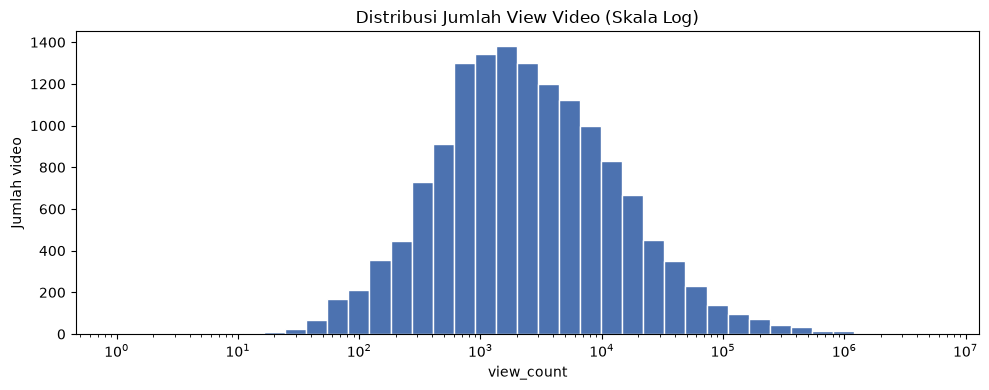

In [38]:
views = videos["view_count"].dropna().astype(float)
views = views[views > 0]
log_bins = np.logspace(0, np.log10(views.max()) + 0.1, 40).tolist()  # Bin berjarak rata pada skala log.
plt.figure(figsize=(10, 4))
plt.hist(views, bins=log_bins, color="#4C72B0", edgecolor="white")
plt.xscale("log")
plt.title("Distribusi Jumlah View Video (Skala Log)")
plt.xlabel("view_count")
plt.ylabel("Jumlah video")
save_figure("video_view_distribution")

### 3.1.5 Jumlah Video per Channel

Menampilkan jumlah video MBG per channel, termasuk channel dengan 0 video, agar terlihat bahwa channel tersebut sudah dicari tetapi tidak memiliki video yang memenuhi kriteria.

,channel_name,category,method,n_videos
0,KOMPASTV,national_media,search,2019
8,GARUDA TV,national_media,search,1238
23,SINDOnews,national_media,search,1121
3,tvOneNews,national_media,search,1107
13,Liputan6,national_media,search,1033
5,BeritaSatu,national_media,search,997
10,Kompas.com,national_media,search,984
4,Official iNews,national_media,search,962
1,CNN Indonesia,national_media,search,849
2,METRO TV,national_media,search,838


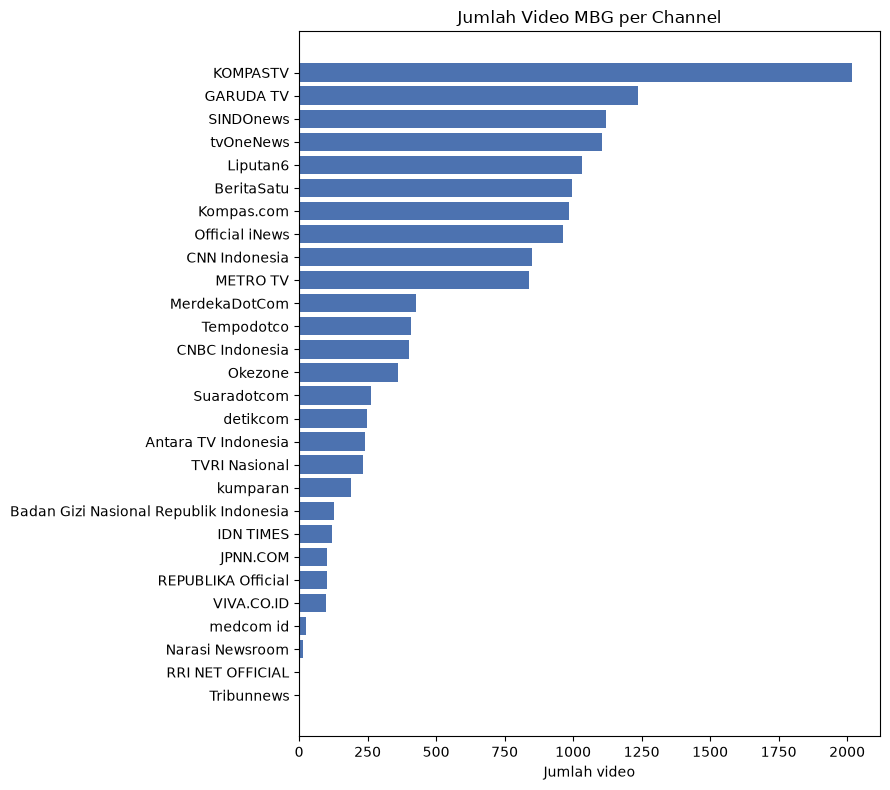

In [39]:
video_per_channel = (df_channels[["channel_name", "category", "method"]]
                     .merge(videos.groupby("channel_name")["video_id"].count().rename("n_videos"),
                            on="channel_name", how="left")
                     .fillna({"n_videos": 0})
                     .astype({"n_videos": int})
                     .sort_values("n_videos", ascending=False))
display(video_per_channel)

plt.figure(figsize=(9, 8))
data_plot = video_per_channel.sort_values("n_videos")
plt.barh(data_plot["channel_name"], data_plot["n_videos"], color="#4C72B0")
plt.title("Jumlah Video MBG per Channel")
plt.xlabel("Jumlah video")
save_figure("video_per_channel")

### 3.1.6 Perbandingan Media Nasional dan BGN

Membandingkan jumlah video dan rata-rata engagement antara channel media nasional dan channel pemerintah (BGN), karena keduanya mewakili jenis sumber yang berbeda.

In [40]:
category_summary = videos.groupby("category").agg(
    n_videos=("video_id", "count"),
    median_views=("view_count", "median"),
    median_comments=("comment_count", "median"),
    total_comments_api=("comment_count", "sum"),
)
display(category_summary)

,n_videos,median_views,median_comments,total_comments_api
category,,,,
government,129,750.0,4.0,1044
national_media,14386,2193.5,6.0,817709


### 3.1.7 Tren Jumlah Video per Bulan

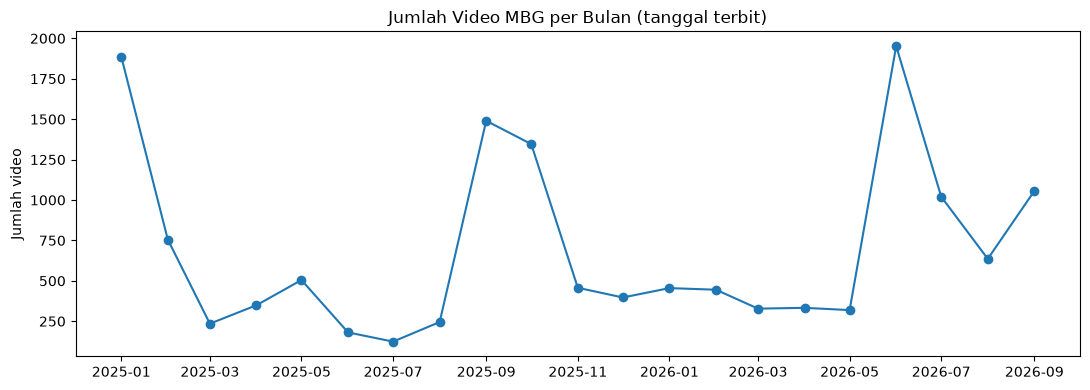

In [41]:
video_per_month = videos.set_index("published_at").resample("MS")["video_id"].count()
plt.figure(figsize=(11, 4))
plt.plot(video_per_month.index, video_per_month.values, marker="o")
plt.title("Jumlah Video MBG per Bulan (tanggal terbit)")
plt.ylabel("Jumlah video")
save_figure("video_per_month")

### 3.1.8 Lokasi Keyword MBG dan Video Siaran Langsung

Memeriksa berapa video yang memuat keyword MBG di judul dibanding yang hanya di deskripsi, serta berapa yang berasal dari siaran langsung. Video yang hanya cocok di deskripsi, terutama siaran langsung, berpotensi membahas MBG hanya sekilas sehingga perlu diperhatikan saat analisis.

In [42]:
display(pd.crosstab(videos["mbg_match_field"], videos["was_live"], margins=True,
                    rownames=["mbg_match_field"], colnames=["was_live"]))
print("Metode pencarian:", videos["search_method"].value_counts().to_dict())

was_live,False,True,All
mbg_match_field,,,
description,2586,373,2959
title,10591,965,11556
All,13177,1338,14515


Metode pencarian: {'search': 13813, 'playlist': 702}


### 3.1.9 Frekuensi Kata pada Judul Video

Menghitung 20 kata yang paling sering muncul pada judul video. Stopword umum dan kata keyword MBG itu sendiri (`mbg`, `makan`, `bergizi`, `gratis`) dikecualikan agar kata lain terlihat.

In [43]:
title_words = top_words(videos["title_clean"])
display(title_words)

,word,frequency
0,prabowo,2408
1,bgn,2338
2,keracunan,2290
3,siswa,1491
4,sppg,1233
5,kepala,1225
6,dapur,1181
7,presiden,1006
8,liputan,843
9,sindo,823


### 3.1.10 Wordcloud Judul Video

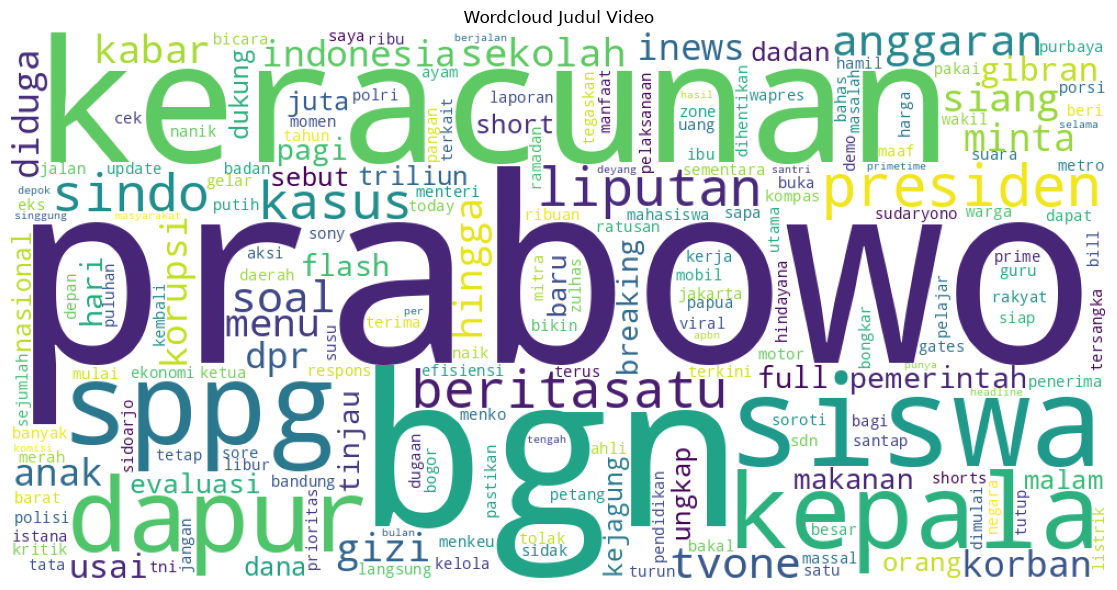

In [44]:
try:
    from wordcloud import WordCloud
    title_freq = Counter(w for t in videos["title_clean"] for w in re.findall(r"[a-z]{3,}", t.lower())
                         if w not in EDA_STOPWORDS)
    if title_freq:
        wordcloud = WordCloud(width=1000, height=500, background_color="white").generate_from_frequencies(title_freq)
        plt.figure(figsize=(12, 6))
        plt.imshow(wordcloud)
        plt.axis("off")
        plt.title("Wordcloud Judul Video")
        save_figure("wordcloud_video_titles")
except ImportError:
    print("Library wordcloud belum terpasang: pip install wordcloud")

### 3.1.11 Korelasi Views, Likes, dan Comments

Menghitung korelasi Spearman (berbasis peringkat), karena lebih tahan terhadap outlier dibanding korelasi Pearson pada data yang sangat timpang.

In [45]:
display(videos[["view_count", "like_count", "comment_count"]].astype("float").corr(method="spearman").round(2))

,view_count,like_count,comment_count
view_count,1.00,0.87,0.77
like_count,0.87,1.00,0.73
comment_count,0.77,0.73,1.00


### 3.1.12 Top 10 Video dengan View Tertinggi

In [46]:
display(videos.nlargest(10, "view_count")[["channel_name", "published_at", "title", "view_count",
                                           "like_count", "comment_count"]])

,channel_name,published_at,title,view_count,like_count,comment_count
6445,Suaradotcom,2025-09-25 13:13:56+00:00,"Lagi, Keracunan Makanan Bergizi Gratis Hebohkan Indonesia! Kali Ini Bandung ...",4727909,70006,20502
6013,Tempodotco,2025-04-19 04:00:06+00:00,Kroni Prabowo dalam Proyek Makan Bergizi Gratis (MBG) | Bocor Alus Politik,2256758,29001,4617
2888,METRO TV,2025-03-12 01:29:43+00:00,Pemerintah Harus Tindak Tegas Korupsi Seperti Harimau #shorts,1861562,62709,3711
52,KOMPASTV,2025-02-20 16:35:57+00:00,"[FULL] Ferry: ASN Terdampak Efisiensi Anggaran, Kemewahan Pejabat Tak Digang...",1858191,18967,2768
5963,Tempodotco,2025-02-08 04:00:06+00:00,Kongkalikong DPR-Pemerintah Memotong Anggaran | Jelasin Dong! X BAP,1691190,18857,3866
3856,Narasi Newsroom,2025-03-03 20:00:29+00:00,Danantara dan Makan Bergizi Gratis: Solusi atau Beban Baru Negara? | Bicara,1092363,8267,1392
6197,Tempodotco,2026-06-20 04:00:06+00:00,Benci-Rindu Hubungan Prabowo-Jokowi dan Blusukan Gibran ke Daerah | Bocor Al...,1041692,9480,1834
14476,Kompas.com,2026-07-16 09:58:20+00:00,"DPR Terdiam, Perwakilan Ibu Bongkar ""Dosa"" MBG, Sebut Proyek Paling Menghina...",1041288,16423,7257
3722,TVRI Nasional,2026-02-05 08:18:32+00:00,Aksi Petugas SPPG Menjawab Permintaan Pelajar Di Randugunting Tegal,1030294,7772,169
608,KOMPASTV,2025-09-24 13:52:47+00:00,"Keracunan MBG, Orang Tua Siswa Minta Ada Komite Pengawas dan Evaluasi Dapur ...",959690,957,457


## 3.2. Analisis Dataset Comment

### 3.2.1 Informasi Struktur Dataset

In [47]:
print("Jumlah baris, kolom:", comments.shape)
comments.info()
display(comments.head(3))

Jumlah baris, kolom: (818708, 17)
<class 'pandas.DataFrame'>
RangeIndex: 818708 entries, 0 to 818707
Data columns (total 17 columns):
 #   Column               Non-Null Count   Dtype              
---  ------               --------------   -----              
 0   comment_id           818708 non-null  str                
 1   video_id             818708 non-null  str                
 2   parent_comment_id    818708 non-null  str                
 3   is_reply             818708 non-null  bool               
 4   author_hash          818708 non-null  str                
 5   text_raw             818708 non-null  str                
 6   like_count           818708 non-null  Int64              
 7   reply_count          685311 non-null  Int64              
 8   published_at         818708 non-null  datetime64[us, UTC]
 9   updated_at           818708 non-null  datetime64[us, UTC]
 10  collected_at_utc     818707 non-null  datetime64[us, UTC]
 11  text_clean           818708 non-null  str 

,comment_id,video_id,parent_comment_id,is_reply,author_hash,text_raw,like_count,reply_count,published_at,updated_at,collected_at_utc,text_clean,is_repeated_text,is_suspected_spam,location_names,province,location_match_type
0,UgxL3NUAQd_iGcJcNqh4AaABAg,Qfd5LzSl_VQ,,False,86586b20cd3ba53a,Kodok kungfu hustle,1,0,2026-04-17 10:02:21+00:00,2026-04-17 10:02:21+00:00,2026-10-21 07:23:20.342732+00:00,Kodok kungfu hustle,False,False,,,
1,UgwFTlHrb_Z8tNQheqN4AaABAg,Qfd5LzSl_VQ,,False,4ba9192b53ee2c4c,Jahat banget anggaran negara dihambur2kan demi program ga jelas macam MBG in...,0,0,2026-04-17 06:52:53+00:00,2026-04-17 06:52:53+00:00,2026-10-21 07:23:20.342750+00:00,Jahat banget anggaran negara dihambur2kan demi program ga jelas macam MBG in...,False,False,,,
2,UgwpiRN_oSora4zPACp4AaABAg,Qfd5LzSl_VQ,,False,db235fb132dd44a8,"Gara Mulyono wong solo, angkat orang jadi kepala bgm, ngabisin uang rakyat s...",0,0,2026-04-17 06:00:53+00:00,2026-04-17 06:00:53+00:00,2026-10-21 07:23:20.342757+00:00,"Gara Mulyono wong solo, angkat orang jadi kepala bgm, ngabisin uang rakyat s...",False,False,,,


### 3.2.2 Mengecek Missing Values dan Duplikasi

`author_hash` kosong berarti API tidak menyertakan ID channel penulis (misalnya akun yang sudah dihapus). `reply_count` hanya terisi untuk comment utama.

In [48]:
comment_missing = count_missing(comments)
display(comment_missing[comment_missing["missing"] > 0])
print("Duplikasi comment_id:", int(comments["comment_id"].duplicated().sum()))

,column,missing,missing_pct
2,parent_comment_id,685311,83.71
7,reply_count,133397,16.29
10,collected_at_utc,1,0.00
14,location_names,803289,98.12
15,province,803289,98.12
16,location_match_type,803289,98.12


Duplikasi comment_id: 0


### 3.2.3 Comment Utama dan Reply

In [49]:
comment_type = comments["is_reply"].map({False: "comment utama", True: "reply"}).value_counts()
display(comment_type.to_frame("jumlah"))
print("Penulis unik:", comments["author_hash"].replace("", pd.NA).nunique())

,jumlah
is_reply,
comment utama,685311
reply,133397


Penulis unik: 352874


### 3.2.4 Statistik Deskriptif Like dan Panjang Comment

Panjang comment dihitung dalam jumlah kata dari `text_clean`.

In [50]:
comments["n_words"] = comments["text_clean"].str.split().str.len()
display(comments[["like_count", "n_words"]].astype("float").describe().round(1))

,like_count,n_words
count,818708.0,818708.0
mean,1.4,15.7
std,19.5,22.4
min,0.0,1.0
25%,0.0,6.0
50%,0.0,10.0
75%,0.0,19.0
max,5596.0,1512.0


### 3.2.5 Distribusi Panjang Comment

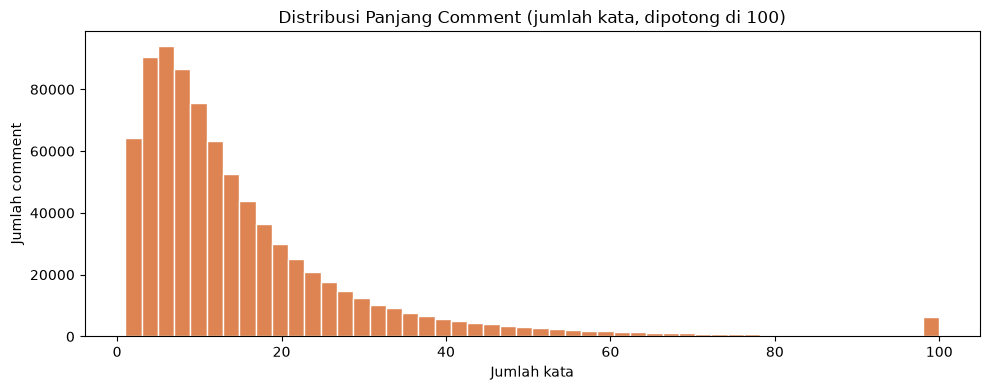

In [51]:
plt.figure(figsize=(10, 4))
plt.hist(comments["n_words"].clip(upper=100), bins=50, color="#DD8452", edgecolor="white")
plt.title("Distribusi Panjang Comment (jumlah kata, dipotong di 100)")
plt.xlabel("Jumlah kata")
plt.ylabel("Jumlah comment")
save_figure("comment_length_distribution")

### 3.2.6 Channel dengan Comment Terbanyak

,n_comments
channel_name,
KOMPASTV,154187
Liputan6,118492
Kompas.com,99007
Official iNews,56865
CNN Indonesia,54581
SINDOnews,53522
tvOneNews,52372
Tempodotco,47029
MerdekaDotCom,34197


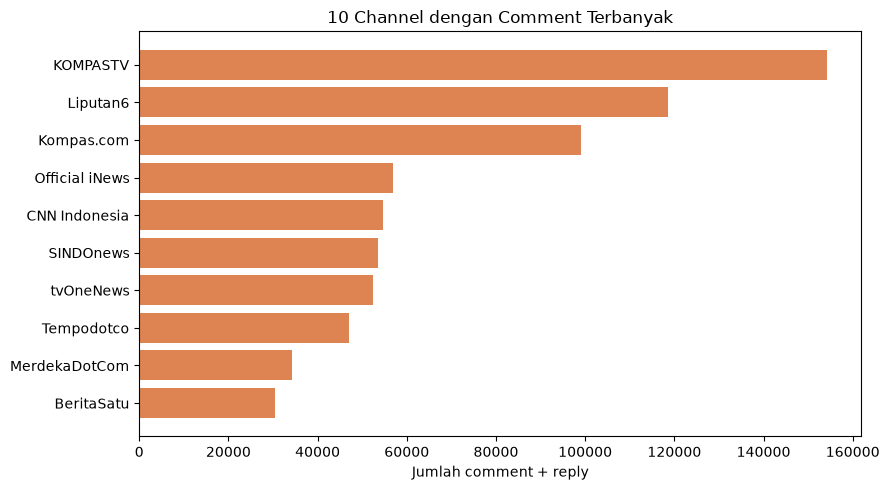

In [52]:
comment_per_channel = (comments.merge(videos[["video_id", "channel_name"]], on="video_id")
                       .groupby("channel_name")["comment_id"].count()
                       .sort_values(ascending=False))
display(comment_per_channel.to_frame("n_comments"))

plt.figure(figsize=(9, 5))
top10 = comment_per_channel.head(10).sort_values()
plt.barh(top10.index, top10.values, color="#DD8452")
plt.title("10 Channel dengan Comment Terbanyak")
plt.xlabel("Jumlah comment + reply")
save_figure("comment_per_channel")

### 3.2.7 Tren Jumlah Comment per Bulan

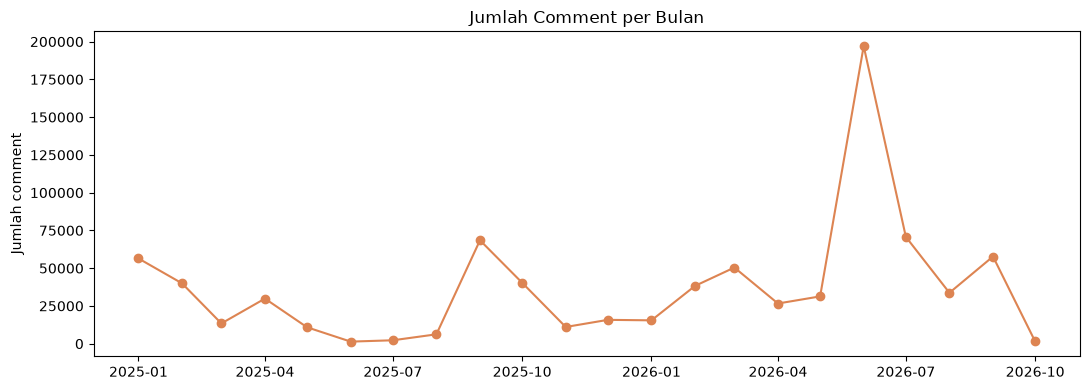

In [53]:
comment_per_month = comments.set_index("published_at").resample("MS")["comment_id"].count()
plt.figure(figsize=(11, 4))
plt.plot(comment_per_month.index, comment_per_month.values, marker="o", color="#DD8452")
plt.title("Jumlah Comment per Bulan")
plt.ylabel("Jumlah comment")
save_figure("comment_per_month")

### 3.2.8 Frekuensi Kata pada Comment

In [54]:
comment_words = top_words(comments["text_clean"], n=30)
display(comment_words)

,word,frequency
0,anak,91199
1,rakyat,86526
2,orang,68202
3,gak,60219
4,pak,60049
5,banyak,55283
6,korupsi,51214
7,negara,51071
8,sekolah,50577
9,indonesia,47965


### 3.2.9 Wordcloud Comment

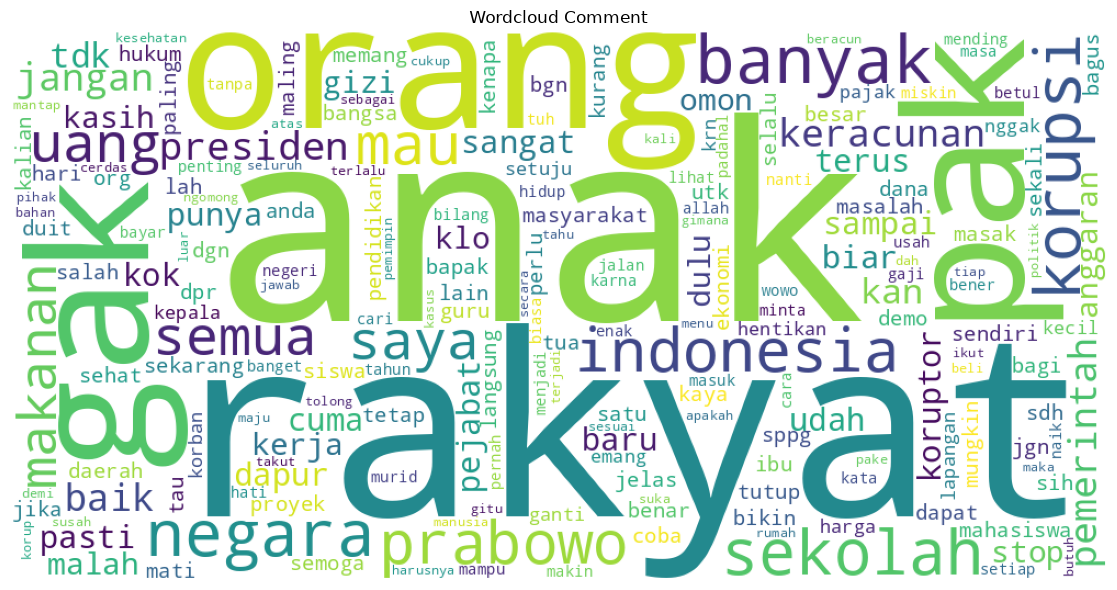

In [55]:
try:
    from wordcloud import WordCloud
    # Frekuensi kata dihitung dulu (hemat memori dibanding menggabungkan seluruh comment menjadi satu teks).
    comment_freq = Counter(w for t in comments["text_clean"] for w in re.findall(r"[a-z]{3,}", t.lower())
                           if w not in EDA_STOPWORDS)
    if comment_freq:
        wordcloud = WordCloud(width=1000, height=500, background_color="white").generate_from_frequencies(comment_freq)
        plt.figure(figsize=(12, 6))
        plt.imshow(wordcloud)
        plt.axis("off")
        plt.title("Wordcloud Comment")
        save_figure("wordcloud_comments")
except ImportError:
    print("Library wordcloud belum terpasang: pip install wordcloud")

### 3.2.10 Aktivitas Penulis, Teks Berulang, dan Spam

Memeriksa indikasi akun yang sangat aktif, teks yang berulang, dan comment yang ditandai spam. Hasil ini menjadi bahan bagian kualitas data (C5) pada laporan.

In [56]:
author_activity = comments[comments["author_hash"] != ""].groupby("author_hash")["comment_id"].count()
print("Rata-rata comment per penulis:", round(author_activity.mean(), 2))
print("Penulis dengan >= 20 comment :", int((author_activity >= 20).sum()))
print("Comment teks berulang        :", int(comments["is_repeated_text"].sum()))
print("Comment dicurigai spam       :", int(comments["is_suspected_spam"].sum()),
      "| pada", comments.loc[comments["is_suspected_spam"], "video_id"].nunique(), "video")

repeated = (comments[comments["is_repeated_text"]]["text_clean"].str.lower()
            .value_counts().head(10).to_frame("n_occurrences"))
display(repeated)

# Contoh acak comment yang ditandai spam, untuk pemeriksaan manual.
spam_comments = comments[comments["is_suspected_spam"]]
if len(spam_comments):
    display(spam_comments.sample(min(10, len(spam_comments)), random_state=42)[["video_id", "text_clean"]])

Rata-rata comment per penulis: 2.32
Penulis dengan >= 20 comment : 3152
Comment teks berulang        : 52471
Comment dicurigai spam       : 2236 | pada 215 video


,n_occurrences
text_clean,
stop mbg,1077
😂😂😂,665
setuju,602
😂,578
mantap,558
betul,397
😂😂😂😂,365
omon omon,364
bubarkan mbg,361


,video_id,text_clean
651394,RtYtYyzvhJw,Tmen2 gw udah main di 𝗪𝙄𝗡30𝟛 gw nyusul
189011,adnpV3PqNRs,jepey gampang banget di 𝘈𝐆𝙐𝑆𝐓𝙊𝙏𝙊
480378,ZwSLzGb6vLA,udh cobain 𝐉𝗣𝑻𝑶𝗚𝑬𝗟77 bray?
344772,zJ30PwTgBOA,Jepe terus di 𝑪𝑼𝑨𝑵𝟑𝟐𝟖
646742,-815lbgamT8,"Main di 𝘿𝐸WАD𝙊𝙍𝐴 bikin hasil tak terduga, senang banget!"
38647,2hcqWmOt5gA,"Beneran top, nggak nyesel coba 𝐉𝗣𝑻𝑶𝗚𝑬𝗟77!."
38681,2hcqWmOt5gA,"𝗞𝗢𝗜𝗦𝗟𝗢𝗧, daftar cepat, main langsung!"
546673,iAb_UAUD7z8,14:15 Wajib viral ini!𝗕𝗘𝗥𝗞𝗔𝗛𝟵𝟵
495867,REqXiViQA6o,"Aku baru aja coba, dan langsung dapet jakpot gede di 𝑺𝑼𝑯𝑼𝟑𝟐𝟖. Rasanya gak pe..."
120906,7X-NKb9OZZY,"Parah! 𝑻𝑶𝑻𝑶𝟑𝟐𝟖 bikin nagih banget, susah berhenti!"


### 3.2.11 Top 10 Comment dengan Like Tertinggi

In [57]:
display(comments.nlargest(10, "like_count")[["video_id", "text_clean", "like_count", "published_at"]])

,video_id,text_clean,like_count,published_at
65619,WjNRWr4lJqk,"Stop MBG, berikan saja dalam bentuk uang, hanya ibu yg bisa masak terbaik ut...",5596,2026-02-06 07:05:54+00:00
203467,9pYX9h3HHyg,"Yang muak sama si tua rakus ini, mana jempolnya",5033,2025-10-17 15:42:50+00:00
67757,WjNRWr4lJqk,"liat berita jd takut sendiri,, anak sy sekolah disemarang,,, Alhamdulillah g...",4099,2025-12-08 08:07:44+00:00
786981,TDGJvq7sHxw,Sering sering gini admin metro Rakyat butuh pembawa acara sperti ini jaman skrg,3508,2025-03-16 07:55:03+00:00
357653,gP0YCMCJnjA,"1:30:02 mba Nana ngotot karena tahu jawaban Prabowo ngelantur, nanya kekhawa...",3286,2025-04-07 12:44:04+00:00
356360,gP0YCMCJnjA,Timestamp -- Silahkan klik tanda waktu ke topik yang lo paling pengen tahu. ...,3164,2025-04-07 15:17:16+00:00
59631,WjNRWr4lJqk,Melihat tapi buta mendengar tapi tuli... Itulah pemimpin negeri ini...,2861,2026-02-24 12:54:54+00:00
811608,a2WXt0aW76g,"Indonesia mungkin kalah dalam berbagai bidang dan teknologi, tapi percayalah...",2478,2025-04-19 04:32:49+00:00
354180,gP0YCMCJnjA,Satu hal yang terjawab: ternyata problematikanya bukan hanya di orang-orang ...,2358,2025-04-08 06:05:27+00:00
810795,a2WXt0aW76g,Tujuan MBG itu bukan untuk memenuhi gizi anak bangsa...tapi hanya untuk mens...,1856,2025-04-19 05:52:29+00:00


## 3.3. Analisis Dataset Gabungan

### 3.3.1 Jumlah Comment per Video

In [58]:
comment_per_video = comments.groupby("video_id")["comment_id"].count()
comment_per_video = videos[["video_id"]].merge(comment_per_video.rename("n_comments"),
                                                on="video_id", how="left").fillna({"n_comments": 0})
display(comment_per_video["n_comments"].describe().round(1).to_frame())
print("Video tanpa comment:", int((comment_per_video["n_comments"] == 0).sum()))

,n_comments
count,14515.0
mean,56.4
std,304.9
min,0.0
25%,1.0
50%,6.0
75%,27.0
max,20502.0


Video tanpa comment: 2696


### 3.3.2 Kelengkapan Comment Dibanding Data API

Membandingkan jumlah comment yang berhasil dikumpulkan dengan `comment_count` dari API (yang juga menghitung reply). Selisih dapat terjadi karena comment dihapus, tertahan moderasi, atau comment dinonaktifkan.

In [59]:
total_api = int(videos["comment_count"].fillna(0).sum())
print("comment_count menurut API :", total_api)
print("Comment terkumpul         :", len(comments))
if total_api:
    print("Persentase terkumpul      :", round(100 * len(comments) / total_api, 1), "%")
display(df_comment_status["status"].value_counts().to_frame("n_videos"))

comment_count menurut API : 818753
Comment terkumpul         : 818708
Persentase terkumpul      : 100.0 %


,n_videos
status,
completed,11819
no_comments,2690
comments_disabled,6


### 3.3.3 Kemunculan Keyword Keamanan Pangan (Indikasi Awal)

Menghitung berapa video dan comment yang menyebut kelompok keyword terkait masalah keamanan dan kebersihan makanan (sesuai fokus RQ1). Ini hanya **pencocokan kata sederhana** untuk melihat apakah dataset memuat pembahasan yang relevan, bukan hasil *topic modeling*.

,keyword_group,n_videos,n_comments
0,keracunan,3027,30880
1,makanan_basi,167,10345
2,benda_organisme_asing,125,2224
3,kontaminasi_bakteri,141,971
4,kebersihan_higiene,496,3074


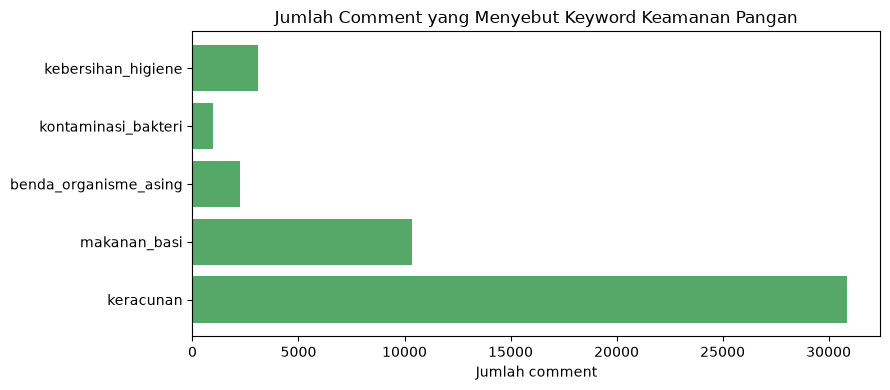

In [60]:
FOOD_SAFETY_KEYWORDS = {
    "keracunan": r"\b(?:keracunan|diare|mual|muntah)\b",
    "makanan_basi": r"\b(?:basi|busuk|berbau|bau)\b",
    "benda_organisme_asing": r"\b(?:belatung|ulat|cacing|kecoa|lalat|rambut|plastik)\b",
    "kontaminasi_bakteri": r"\b(?:bakteri|kontaminasi|terkontaminasi|e\.?\s?coli|salmonella)\b",
    "kebersihan_higiene": r"\b(?:higiene|higienis|kebersihan|jorok|kotor|sanitasi)\b",
}

rows = []
for group, pattern in FOOD_SAFETY_KEYWORDS.items():
    video_text = videos["title_clean"] + " " + videos["description_clean"]
    rows.append({"keyword_group": group,
                 "n_videos": int(video_text.str.contains(pattern, case=False, regex=True).sum()),
                 "n_comments": int(comments["text_clean"].str.contains(pattern, case=False, regex=True).sum())})
keyword_summary = pd.DataFrame(rows)
display(keyword_summary)

plt.figure(figsize=(9, 4))
plt.barh(keyword_summary["keyword_group"], keyword_summary["n_comments"], color="#55A868")
plt.title("Jumlah Comment yang Menyebut Keyword Keamanan Pangan")
plt.xlabel("Jumlah comment")
save_figure("food_safety_keywords")

### 3.3.4 Sebaran Lokasi yang Disebut (Indikasi Awal RQ2)

Menghitung jumlah video dan comment yang menyebut setiap provinsi (hasil bagian 2.4), termasuk video yang juga menyebut keyword keracunan. Satu video/comment dapat menyebut lebih dari satu provinsi. Tabel disimpan ke `data/interim/youtube/location_per_province.csv`. Ini masih **indikasi awal**: Jakarta, misalnya, sering muncul sebagai lokasi pernyataan pejabat, bukan lokasi kejadian.

,n_videos,n_videos_keracunan,n_comments
province,,,
DKI Jakarta,2426,279,1778
Jawa Barat,1523,551,2777
Jawa Tengah,876,372,2020
Jawa Timur,820,320,1972
Sumatera Utara,276,161,480
Banten,200,19,540
Papua,198,20,2325
Daerah Istimewa Yogyakarta,192,87,321
Sulawesi Selatan,178,42,249


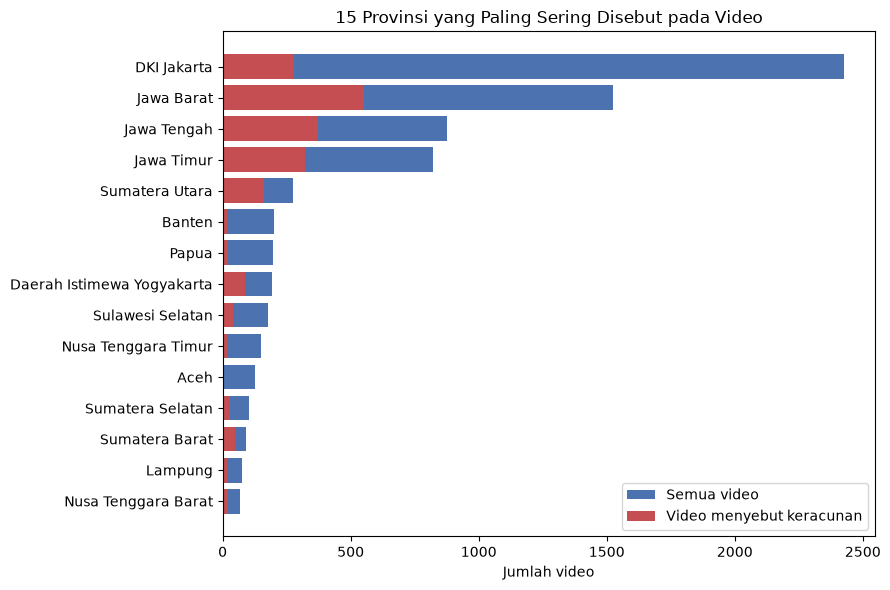

In [61]:
def count_by_province(df):
    provinces = df["province"].str.split("; ").explode()
    return provinces[provinces != ""].value_counts()


poisoning_pattern = r"\b(?:keracunan|diare|mual|muntah)\b"
poisoning_videos = videos[(videos["title_clean"] + " " + videos["description_clean"])
                          .str.contains(poisoning_pattern, case=False, regex=True)]
location_per_province = (pd.DataFrame({"n_videos": count_by_province(videos),
                                       "n_videos_keracunan": count_by_province(poisoning_videos),
                                       "n_comments": count_by_province(comments)})
                         .fillna(0).astype(int).sort_values("n_videos", ascending=False))
location_per_province.index.name = "province"
display(location_per_province)
save_csv(location_per_province.reset_index(), OUTPUT_DIR / "location_per_province.csv")

top_provinces = location_per_province.head(15).iloc[::-1]
plt.figure(figsize=(9, 6))
plt.barh(top_provinces.index, top_provinces["n_videos"], color="#4C72B0", label="Semua video")
plt.barh(top_provinces.index, top_provinces["n_videos_keracunan"], color="#C44E52", label="Video menyebut keracunan")
plt.title("15 Provinsi yang Paling Sering Disebut pada Video")
plt.xlabel("Jumlah video")
plt.legend()
save_figure("location_per_province")

### 3.3.5 Ringkasan Dataset

In [62]:
summary = {
    "n_channels": len(df_channels),
    "n_videos": len(videos),
    "n_top_level_comments": int((~comments["is_reply"]).sum()),
    "n_replies": int(comments["is_reply"].sum()),
    "n_unique_authors": int(comments["author_hash"].replace("", pd.NA).nunique()),
    "n_videos_with_location": int((videos["location_names"] != "").sum()),
    "n_comments_with_location": int((comments["location_names"] != "").sum()),
    "first_video_utc": videos["published_at"].min(),
    "last_video_utc": videos["published_at"].max(),
    "collection_complete": COLLECTION_COMPLETE,
}
df_summary = pd.DataFrame(list(summary.items()), columns=["metric", "value"])
display(df_summary)
save_csv(df_summary, OUTPUT_DIR / "dataset_summary.csv")
save_csv(video_per_channel, OUTPUT_DIR / "video_per_channel.csv")

,metric,value
0,n_channels,28
1,n_videos,14515
2,n_top_level_comments,685311
3,n_replies,133397
4,n_unique_authors,352874
5,n_videos_with_location,7189
6,n_comments_with_location,15419
7,first_video_utc,2025-01-05 22:34:42+00:00
8,last_video_utc,2026-09-30 16:11:20+00:00
9,collection_complete,False


# 4. Keterbatasan dan Pertimbangan Etika

**Keterbatasan cakupan**

* Search API bergantung pada indeks pencarian YouTube dan tidak menjamin seluruh video MBG ditemukan. Video yang membahas MBG hanya di audio tanpa menyebutnya di judul/deskripsi juga tidak terjangkau.
* Video yang dihapus/privat serta comment yang dihapus atau tertahan moderasi tidak dapat diambil. Video dengan comment dinonaktifkan dicatat terpisah.
* Dataset hanya mewakili penonton YouTube yang berkomentar di 28 channel terpilih, bukan seluruh masyarakat Indonesia.
* Kata `MBG` dapat bermakna lain. Video yang hanya cocok di deskripsi (kolom `mbg_match_field`) perlu diperiksa saat analisis.
* Lokasi diekstraksi dengan pencocokan kamus wilayah, sehingga hanya menangkap nama wilayah yang **disebut** di teks dan belum tentu lokasi kejadian. Nama di luar kamus (desa, kecamatan, nama sekolah) dan salah ketik di luar daftar alias tidak terdeteksi, sedangkan nama ambigu tanpa kata konteks dilewati. "Papua" dapat berarti Provinsi Papua atau seluruh Tanah Papua, dan Jakarta sering muncul sebagai lokasi pernyataan pejabat.

**Etika dan privasi**

* Hanya konten publik yang diambil, melalui API resmi sesuai Ketentuan Layanan YouTube API.
* Nama tampilan penulis tidak diminta dari API; ID penulis diganti pseudonim berbasis *salt* lokal.
* Data mentah, *salt*, dan API key tidak dipublikasikan (dikecualikan oleh `.gitignore`); repositori hanya memuat kode dan dokumentasi.
* Kebijakan YouTube API meminta data yang disimpan diperbarui atau dihapus secara berkala (30 hari); dataset dipakai terbatas untuk keperluan tugas kuliah.